# Lab01 - sprint 1

## Навигация по документу
1. [Введение и описание датасета](#scrollTo=57S8bI4IZ_w_)
2. [Random Variable 01 (Энергия активации Ea)](#scrollTo=rEvhRFRNM3FK)
3. [Random Variable 02 (Логарифм предэкспоненциального множителя ln A)](#scrollTo=Y7U3SPUsM9jo)
4. [Состоятельность оценок и выборки](#scrollTo=goQ7FCD_NCcb)
5. [Random Variable 03 (Константа скорости реакции k_air)](#scrollTo=0pEc6FVdNOk4)
6. [Проверка зависимости величин и статистических гипотез](#scrollTo=MHesW2u0NSVO)
7. [Дополнительное исследование (наклон КЭ по классам алканов)](#scrollTo=41ccuxiqN65b)
8. [Итоги Спринта 1](#scrollTo=8z0hfs8fNlFI)
9. [Sprint 2 (Генератор случайных чисел)](#scrollTo=jA2-7lzVTRf0)
10. [Автотесты и моделирование Монте-Карло](#scrollTo=8td2T-hRNzZe)
11. [Общие выводы и список литературы](#scrollTo=VpjYlNle5T4G)

## Введение и описание датасета
Я сейчас занимаюсь научной работой в этой области, поэтому выбор темы был очевиден : )

В этой лабораторной работе я исследую кинетические параметры газофазных реакций радикалов гидроксила (OH) с разными классами алканов (линейными, разветвленными и циклическими) при температурах от 273 до 323 К в среде воздуха (Air) и чистого азота (N2).

Данные для анализа я взяла из статьи Y. Xin et al. (https://doi.org/10.5194/egusphere-2023-2802), где методом относительных скоростей измерены константы скорости реакций радикалов OH с 25 алканами (от C3 до C11) при шести температурах от 273 до 323 К в атмосфере воздуха и чистого азота.

Главная идея моей работы — проверить природу так называемого кинетического компенсационного эффекта (КЭ), то есть линейной зависимости между энергией активации Ea и логарифмом предэкспоненциального множителя ln A. На основе современных статей по статистике уравнения Аррениуса (Zhen et al (https://doi.org/10.1016/j.electacta.2026.149160); Rodellar et al (https://doi.org/10.1021/acscatal.6c03363); Lizée et al (https://doi.org/10.1039/d5fd00127g)) я проверяю, связана ли эта корреляция с реальным строением молекулы или возникает как математический артефакт при линеаризации Аррениуса в узком температурном диапазоне при наличии экспериментального шума (критический наклон 1 / (R * T_avg)). Также я проверяю гипотезы авторов исходных данных о влиянии класса углеводорода и газа-разбавителя (Air против N2), а во втором спринте строю и тестирую генератор случайных кинетических параметров.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### Сбор и чистка данных

Данные я переносила вручную из таблицы Table S2. Rate constants for OH + Alkanes in N2 and Air at 273-323 K. в дополнительных материалах (Supplementary: Material) к статье Xin et al. (https://doi.org/10.5194/egusphere-2023-2802). Взяла 25 алканов (линейные, разветвленные и циклические, от C3 до C11) при 6 температурах от 273 до 323 К. Всего получилось 150 строк.

При проверке нашлось 4 пропуска (None) и 1 экспериментальный выброс:
- У 3-Methylhexane при 303 К в азоте в PDF склеились два числа (3.143.55). Я пробовала восстановить значение по графику Аррениуса из статьи (Figure 6 (d)), но оценить число с нужной точностью не удалось. Чтобы не вносить ошибку в регрессию, поставила None.
- У Propane (273 и 283 К) и n-Undecane (273 К) в статье нет значений погрешности k_air_sigma. На расчет Ea и ln A это не влияет, поэтому сами константы оставила.
- У n-Octane при 323 К в воздухе в таблице стоит аномально низкое значение (5.90e-12, хотя при 313 К было 8.82e-12, а в азоте при 323 К — 8.95e-12).



In [2]:
data = [
    # 2,3-Dimethylbutane (branched, C6)
    ("2,3-Dimethylbutane","branched",6,273,5.10e-12,0.05e-12,5.09e-12),
    ("2,3-Dimethylbutane","branched",6,283,5.33e-12,0.07e-12,5.27e-12),
    ("2,3-Dimethylbutane","branched",6,293,5.55e-12,0.09e-12,5.39e-12),
    ("2,3-Dimethylbutane","branched",6,303,5.60e-12,0.04e-12,5.64e-12),
    ("2,3-Dimethylbutane","branched",6,313,5.70e-12,0.01e-12,5.68e-12),
    ("2,3-Dimethylbutane","branched",6,323,5.82e-12,0.01e-12,5.76e-12),
    # Methylcyclopentane (cyclic, C6)
    ("Methylcyclopentane","cyclic",6,273,6.44e-12,0.03e-12,6.32e-12),
    ("Methylcyclopentane","cyclic",6,283,6.43e-12,0.18e-12,6.56e-12),
    ("Methylcyclopentane","cyclic",6,293,6.66e-12,0.08e-12,6.80e-12),
    ("Methylcyclopentane","cyclic",6,303,6.95e-12,0.07e-12,7.11e-12),
    ("Methylcyclopentane","cyclic",6,313,7.24e-12,0.01e-12,7.09e-12),
    ("Methylcyclopentane","cyclic",6,323,7.33e-12,0.05e-12,7.31e-12),
    # n-Heptane (linear, C7)
    ("n-Heptane","linear",7,273,5.37e-12,0.17e-12,5.37e-12),
    ("n-Heptane","linear",7,283,5.81e-12,0.09e-12,5.95e-12),
    ("n-Heptane","linear",7,293,6.16e-12,0.23e-12,6.19e-12),
    ("n-Heptane","linear",7,303,6.58e-12,0.06e-12,6.52e-12),
    ("n-Heptane","linear",7,313,7.09e-12,0.01e-12,6.66e-12),
    ("n-Heptane","linear",7,323,7.22e-12,0.03e-12,6.93e-12),
    # 3-Methylheptane (branched, C8)
    ("3-Methylheptane","branched",8,273,6.61e-12,0.07e-12,6.74e-12),
    ("3-Methylheptane","branched",8,283,7.06e-12,0.02e-12,7.29e-12),
    ("3-Methylheptane","branched",8,293,7.58e-12,0.36e-12,7.66e-12),
    ("3-Methylheptane","branched",8,303,7.93e-12,0.24e-12,8.14e-12),
    ("3-Methylheptane","branched",8,313,8.34e-12,0.38e-12,8.13e-12),
    ("3-Methylheptane","branched",8,323,8.49e-12,0.01e-12,8.36e-12),
    # n-Octane (linear, C8)
    ("n-Octane","linear",8,273,6.83e-12,0.31e-12,6.70e-12),
    ("n-Octane","linear",8,283,7.29e-12,0.03e-12,7.62e-12),
    ("n-Octane","linear",8,293,7.60e-12,0.10e-12,7.78e-12),
    ("n-Octane","linear",8,303,8.17e-12,0.04e-12,8.38e-12),
    ("n-Octane","linear",8,313,8.82e-12,0.22e-12,8.70e-12),
    ("n-Octane","linear",8,323,5.90e-12,0.29e-12,8.95e-12), # Air: аномально низкое значение, выброс
    # Propane (linear, C3)
    ("Propane","linear",3,273,7.09e-13,None,6.97e-13), # в статье нет значения погрешности k_air_sigma
    ("Propane","linear",3,283,8.97e-13,None,8.75e-13), # в статье нет значения погрешности k_air_sigma
    ("Propane","linear",3,293,1.01e-12,0.13e-12,9.14e-13),
    ("Propane","linear",3,303,9.91e-13,0.63e-13,1.04e-12),
    ("Propane","linear",3,313,1.15e-12,0.05e-12,1.12e-12),
    ("Propane","linear",3,323,1.22e-12,0.28e-12,1.23e-12),
    # Isobutane (branched, C4)
    ("Isobutane","branched",4,273,1.46e-12,0.14e-12,1.41e-12),
    ("Isobutane","branched",4,283,1.78e-12,0.09e-12,1.68e-12),
    ("Isobutane","branched",4,293,1.83e-12,0.11e-12,1.85e-12),
    ("Isobutane","branched",4,303,2.07e-12,0.27e-12,2.09e-12),
    ("Isobutane","branched",4,313,2.08e-12,0.13e-12,2.17e-12),
    ("Isobutane","branched",4,323,2.32e-12,0.05e-12,2.34e-12),
    # n-Butane (linear, C4)
    ("n-Butane","linear",4,273,1.32e-12,0.58e-12,9.34e-13),
    ("n-Butane","linear",4,283,1.73e-12,0.30e-12,1.86e-12),
    ("n-Butane","linear",4,293,1.92e-12,0.02e-12,2.05e-12),
    ("n-Butane","linear",4,303,2.23e-12,0.15e-12,2.34e-12),
    ("n-Butane","linear",4,313,2.37e-12,0.15e-12,2.51e-12),
    ("n-Butane","linear",4,323,2.57e-12,0.13e-12,2.68e-12),
    # Isopentane (branched, C5)
    ("Isopentane","branched",5,273,2.82e-12,0.03e-12,2.86e-12),
    ("Isopentane","branched",5,283,3.08e-12,0.26e-12,3.01e-12),
    ("Isopentane","branched",5,293,3.26e-12,0.27e-12,3.32e-12),
    ("Isopentane","branched",5,303,3.39e-12,0.43e-12,3.26e-12),
    ("Isopentane","branched",5,313,3.56e-12,0.08e-12,3.47e-12),
    ("Isopentane","branched",5,323,3.64e-12,0.27e-12,3.58e-12),
    # n-Pentane (linear, C5)
    ("n-Pentane","linear",5,273,2.86e-12,0.08e-12,2.71e-12),
    ("n-Pentane","linear",5,283,3.02e-12,0.03e-12,2.92e-12),
    ("n-Pentane","linear",5,293,3.12e-12,0.24e-12,3.15e-12),
    ("n-Pentane","linear",5,303,3.25e-12,0.39e-12,3.36e-12),
    ("n-Pentane","linear",5,313,3.35e-12,0.30e-12,3.49e-12),
    ("n-Pentane","linear",5,323,3.41e-12,0.09e-12,3.58e-12),
    # Cyclopentane (cyclic, C5)
    ("Cyclopentane","cyclic",5,273,3.75e-12,0.20e-12,3.66e-12),
    ("Cyclopentane","cyclic",5,283,4.08e-12,0.03e-12,4.14e-12),
    ("Cyclopentane","cyclic",5,293,4.57e-12,0.10e-12,4.45e-12),
    ("Cyclopentane","cyclic",5,303,4.72e-12,0.01e-12,4.72e-12),
    ("Cyclopentane","cyclic",5,313,5.18e-12,0.04e-12,4.92e-12),
    ("Cyclopentane","cyclic",5,323,5.26e-12,0.02e-12,5.27e-12),
    # 2,2-Dimethylbutane (branched, C6)
    ("2,2-Dimethylbutane","branched",6,273,1.25e-12,0.01e-12,1.25e-12),
    ("2,2-Dimethylbutane","branched",6,283,1.46e-12,0.10e-12,1.49e-12),
    ("2,2-Dimethylbutane","branched",6,293,1.74e-12,0.02e-12,1.63e-12),
    ("2,2-Dimethylbutane","branched",6,303,1.85e-12,0.14e-12,1.92e-12),
    ("2,2-Dimethylbutane","branched",6,313,2.03e-12,0.05e-12,2.06e-12),
    ("2,2-Dimethylbutane","branched",6,323,2.06e-12,0.05e-12,2.17e-12),
    # 2-Methylpentane (branched, C6)
    ("2-Methylpentane","branched",6,273,3.91e-12,0.01e-12,3.85e-12),
    ("2-Methylpentane","branched",6,283,4.17e-12,0.14e-12,4.22e-12),
    ("2-Methylpentane","branched",6,293,4.62e-12,0.01e-12,4.52e-12),
    ("2-Methylpentane","branched",6,303,4.74e-12,0.01e-12,4.79e-12),
    ("2-Methylpentane","branched",6,313,5.00e-12,0.15e-12,4.85e-12),
    ("2-Methylpentane","branched",6,323,5.17e-12,0.01e-12,5.11e-12),
    # 3-Methylpentane (branched, C6)
    ("3-Methylpentane","branched",6,273,3.68e-12,0.07e-12,3.79e-12),
    ("3-Methylpentane","branched",6,283,4.03e-12,0.08e-12,4.30e-12),
    ("3-Methylpentane","branched",6,293,4.33e-12,0.26e-12,4.47e-12),
    ("3-Methylpentane","branched",6,303,4.61e-12,0.17e-12,4.88e-12),
    ("3-Methylpentane","branched",6,313,4.63e-12,0.38e-12,4.91e-12),
    ("3-Methylpentane","branched",6,323,5.01e-12,0.06e-12,5.08e-12),
    # 2,4-Dimethylpentane (branched, C7)
    ("2,4-Dimethylpentane","branched",7,273,3.84e-12,0.04e-12,3.84e-12),
    ("2,4-Dimethylpentane","branched",7,283,4.12e-12,0.14e-12,4.19e-12),
    ("2,4-Dimethylpentane","branched",7,293,4.38e-12,0.13e-12,4.45e-12),
    ("2,4-Dimethylpentane","branched",7,303,4.59e-12,0.06e-12,4.62e-12),
    ("2,4-Dimethylpentane","branched",7,313,4.84e-12,0.12e-12,4.69e-12),
    ("2,4-Dimethylpentane","branched",7,323,4.94e-12,0.06e-12,4.81e-12),
    # Cyclohexane (cyclic, C6)
    ("Cyclohexane","cyclic",6,273,5.22e-12,0.18e-12,5.25e-12),
    ("Cyclohexane","cyclic",6,283,5.82e-12,0.15e-12,6.12e-12),
    ("Cyclohexane","cyclic",6,293,6.14e-12,0.17e-12,6.36e-12),
    ("Cyclohexane","cyclic",6,303,6.51e-12,0.25e-12,6.21e-12),
    ("Cyclohexane","cyclic",6,313,6.96e-12,0.25e-12,6.49e-12),
    ("Cyclohexane","cyclic",6,323,6.99e-12,0.05e-12,6.13e-12),
    # 2-Methylhexane (branched, C7)
    ("2-Methylhexane","branched",7,273,5.69e-12,0.01e-12,5.72e-12),
    ("2-Methylhexane","branched",7,283,5.98e-12,0.20e-12,5.89e-12),
    ("2-Methylhexane","branched",7,293,6.12e-12,0.16e-12,6.02e-12),
    ("2-Methylhexane","branched",7,303,6.28e-12,0.06e-12,6.21e-12),
    ("2-Methylhexane","branched",7,313,6.38e-12,0.16e-12,6.33e-12),
    ("2-Methylhexane","branched",7,323,6.49e-12,0.16e-12,6.41e-12),
    # 3-Methylhexane (branched, C7)
    ("3-Methylhexane","branched",7,273,3.11e-12,0.12e-12,3.65e-12),
    ("3-Methylhexane","branched",7,283,3.60e-12,0.76e-12,3.85e-12),
    ("3-Methylhexane","branched",7,293,3.30e-12,0.07e-12,3.39e-12),
    ("3-Methylhexane","branched",7,303,3.48e-12,0.76e-12,None), # N2: склейка 3.143.55 в PDF, исключено
    ("3-Methylhexane","branched",7,313,4.11e-12,0.08e-12,4.79e-12),
    ("3-Methylhexane","branched",7,323,4.52e-12,0.06e-12,4.05e-12),
    # 2,2,4-Trimethylpentane (branched, C8)
    ("2,2,4-Trimethylpentane","branched",8,273,2.55e-12,0.01e-12,2.62e-12),
    ("2,2,4-Trimethylpentane","branched",8,283,2.81e-12,0.10e-12,2.81e-12),
    ("2,2,4-Trimethylpentane","branched",8,293,2.94e-12,0.03e-12,2.97e-12),
    ("2,2,4-Trimethylpentane","branched",8,303,3.17e-12,0.12e-12,3.14e-12),
    ("2,2,4-Trimethylpentane","branched",8,313,3.30e-12,0.16e-12,3.20e-12),
    ("2,2,4-Trimethylpentane","branched",8,323,3.38e-12,0.04e-12,3.33e-12),
    # Methylcyclohexane (cyclic, C7)
    ("Methylcyclohexane","cyclic",7,273,7.53e-12,0.26e-12,7.76e-12),
    ("Methylcyclohexane","cyclic",7,283,8.31e-12,0.08e-12,8.36e-12),
    ("Methylcyclohexane","cyclic",7,293,8.77e-12,0.06e-12,8.62e-12),
    ("Methylcyclohexane","cyclic",7,303,9.18e-12,0.01e-12,9.11e-12),
    ("Methylcyclohexane","cyclic",7,313,9.70e-12,0.10e-12,9.36e-12),
    ("Methylcyclohexane","cyclic",7,323,9.89e-12,0.12e-12,9.55e-12),
    # 2,3,4-Trimethylpentane (branched, C8)
    ("2,3,4-Trimethylpentane","branched",8,273,6.35e-12,0.09e-12,6.37e-12),
    ("2,3,4-Trimethylpentane","branched",8,283,6.56e-12,0.15e-12,6.67e-12),
    ("2,3,4-Trimethylpentane","branched",8,293,6.74e-12,0.11e-12,6.76e-12),
    ("2,3,4-Trimethylpentane","branched",8,303,6.84e-12,0.07e-12,6.85e-12),
    ("2,3,4-Trimethylpentane","branched",8,313,7.07e-12,0.09e-12,6.96e-12),
    ("2,3,4-Trimethylpentane","branched",8,323,7.10e-12,0.10e-12,7.11e-12),
    # 2-Methylheptane (branched, C8)
    ("2-Methylheptane","branched",8,273,6.61e-12,0.78e-12,6.90e-12),
    ("2-Methylheptane","branched",8,283,6.66e-12,0.07e-12,6.94e-12),
    ("2-Methylheptane","branched",8,293,6.26e-12,0.18e-12,6.62e-12),
    ("2-Methylheptane","branched",8,303,6.68e-12,0.46e-12,6.64e-12),
    ("2-Methylheptane","branched",8,313,7.29e-12,0.09e-12,6.88e-12),
    ("2-Methylheptane","branched",8,323,7.34e-12,0.19e-12,7.19e-12),
    # n-Nonane (linear, C9)
    ("n-Nonane","linear",9,273,7.85e-12,0.04e-12,8.38e-12),
    ("n-Nonane","linear",9,283,8.54e-12,0.02e-12,8.80e-12),
    ("n-Nonane","linear",9,293,8.73e-12,0.18e-12,8.87e-12),
    ("n-Nonane","linear",9,303,9.49e-12,0.08e-12,9.53e-12),
    ("n-Nonane","linear",9,313,1.02e-11,0.09e-11,9.70e-12),
    ("n-Nonane","linear",9,323,1.05e-11,0.02e-11,1.01e-11),
    # n-Decane (linear, C10)
    ("n-Decane","linear",10,273,1.04e-11,0.25e-11,9.97e-12),
    ("n-Decane","linear",10,283,9.93e-12,0.04e-12,1.03e-11),
    ("n-Decane","linear",10,293,1.05e-11,0.08e-11,1.05e-11),
    ("n-Decane","linear",10,303,1.10e-11,0.05e-11,1.21e-11),
    ("n-Decane","linear",10,313,1.19e-11,0.03e-11,1.17e-11),
    ("n-Decane","linear",10,323,1.24e-11,0.05e-11,1.20e-11),
    # n-Undecane (linear, C11)
    ("n-Undecane","linear",11,273,1.01e-11,None,1.08e-11), # в статье нет значения погрешности k_air_sigma
    ("n-Undecane","linear",11,283,1.08e-11,0.02e-11,1.10e-11),
    ("n-Undecane","linear",11,293,1.07e-11,0.01e-11,1.12e-11),
    ("n-Undecane","linear",11,303,1.14e-11,0.13e-11,1.19e-11),
    ("n-Undecane","linear",11,313,1.28e-11,0.05e-11,1.22e-11),
    ("n-Undecane","linear",11,323,1.34e-11,0.04e-11,1.29e-11),
]

cols = ["alkane","class","n_carbon","T_K","k_air","k_air_sigma","k_n2"]
df = pd.DataFrame(data, columns=cols)

print("Всего строк:", len(df))
print("Всего алканов:", df["alkane"].nunique())
df.head()

Всего строк: 150
Всего алканов: 25


,alkane,class,n_carbon,T_K,k_air,k_air_sigma,k_n2
0,"2,3-Dimethylbutane",branched,6,273,5.100000e-12,5.000000e-14,5.090000e-12
1,"2,3-Dimethylbutane",branched,6,283,5.330000e-12,7.000000e-14,5.270000e-12
2,"2,3-Dimethylbutane",branched,6,293,5.550000e-12,9.000000e-14,5.390000e-12
3,"2,3-Dimethylbutane",branched,6,303,5.600000e-12,4.000000e-14,5.640000e-12
4,"2,3-Dimethylbutane",branched,6,313,5.700000e-12,1.000000e-14,5.680000e-12


In [3]:
print("Пустых в k_air:", df["k_air"].isna().sum())
print("Пустых в k_n2:", df["k_n2"].isna().sum()) # должен получиться один пропуск
print("Пустых в k_air_sigma:", df["k_air_sigma"].isna().sum()) # должно получиться три пропуска

print("\nСтроки с пропусками:")
print(df[df.isna().any(axis=1)][["alkane", "T_K", "k_air", "k_air_sigma", "k_n2"]])

Пустых в k_air: 0
Пустых в k_n2: 1
Пустых в k_air_sigma: 3

Строки с пропусками:
             alkane  T_K         k_air   k_air_sigma          k_n2
30          Propane  273  7.090000e-13           NaN  6.970000e-13
31          Propane  283  8.970000e-13           NaN  8.750000e-13
105  3-Methylhexane  303  3.480000e-12  7.600000e-13           NaN
144      n-Undecane  273  1.010000e-11           NaN  1.080000e-11


### Расчет энергии активации Ea и предэкспоненциального множителя ln A

Чтобы получить кинетические параметры для каждого алкана, я перевела уравнение Аррениуса в линейный вид:

$$\ln k = \ln A - \frac{E_a}{R} \cdot \frac{1}{T}$$

Для каждого из 25 углеводородов отдельно в воздухе и азоте (всего 50 реакций) строится линейная регрессия $\ln k$ от обратной температуры $1/T$. Угол наклона прямой дает энергию активации $E_a = -\text{наклон} \cdot R / 1000$ (делим на 1000, чтобы перевести из Дж/моль в удобные для химии кДж/моль, $R = 8.314$), а пересечение с осью ординат дает $\ln A$.

In [4]:
R = 8.314
spisok = []

for alkane in df["alkane"].unique():
    sub = df[df["alkane"] == alkane]

    alkane_class = sub["class"].iloc[0]
    n_carbon = sub["n_carbon"].iloc[0]

    # Расчет для воздуха (Air)
    sub_air = sub.dropna(subset=["k_air"])
    x_air = 1 / sub_air["T_K"]
    y_air = np.log(sub_air["k_air"])
    slope, intercept, r, p, err = stats.linregress(x_air, y_air)

    Ea_air = -slope * R / 1000
    spisok.append([alkane, alkane_class, n_carbon, "Air", Ea_air, intercept, r**2, len(sub_air)])

    # Расчет для азота (N2)
    sub_n2 = sub.dropna(subset=["k_n2"])
    x_n2 = 1 / sub_n2["T_K"]
    y_n2 = np.log(sub_n2["k_n2"])
    slope, intercept, r, p, err = stats.linregress(x_n2, y_n2)

    Ea_n2 = -slope * R / 1000
    spisok.append([alkane, alkane_class, n_carbon, "N2", Ea_n2, intercept, r**2, len(sub_n2)])

res_cols = ["alkane", "class", "n_carbon", "gas", "Ea", "ln_A", "R2", "n"]
df_res = pd.DataFrame(spisok, columns=res_cols)

print("Рассчитано строк:", len(df_res))
df_res.head(10)

Рассчитано строк: 50


,alkane,class,n_carbon,gas,Ea,ln_A,R2,n
0,"2,3-Dimethylbutane",branched,6,Air,1.841565,-25.178451,0.956437,6
1,"2,3-Dimethylbutane",branched,6,N2,1.874185,-25.173458,0.968094,6
2,Methylcyclopentane,cyclic,6,Air,2.178560,-24.827144,0.940451,6
3,Methylcyclopentane,cyclic,6,N2,2.121155,-24.846873,0.963343,6
4,n-Heptane,linear,7,Air,4.506770,-23.959642,0.989769,6
5,n-Heptane,linear,7,N2,3.521590,-24.372604,0.960371,6
6,3-Methylheptane,branched,8,Air,3.789077,-24.063427,0.984517,6
7,3-Methylheptane,branched,8,N2,3.108198,-24.331279,0.937126,6
8,n-Octane,linear,8,Air,0.015412,-25.626710,0.000008,6
9,n-Octane,linear,8,N2,4.058191,-23.910095,0.951280,6


In [5]:
print("Статистика R2:")
print(df_res["R2"].describe())

print("\nСтроки, где точек меньше 6:") # в норме по статье 6 температур: 273, 283, 293, 303, 313, 323 К
print(df_res[df_res["n"] < 6][["alkane", "gas", "n", "R2"]])

df.to_csv("table_raw.csv", index=False)
df_res.to_csv("table_res.csv", index=False)
print("\nТаблицы сохранены")

Статистика R2:
count    50.000000
mean      0.883577
std       0.216981
min       0.000008
25%       0.935017
50%       0.964773
75%       0.976986
max       0.992492
Name: R2, dtype: float64

Строки, где точек меньше 6:
            alkane gas  n        R2
35  3-Methylhexane  N2  5  0.369073

Таблицы сохранены


Большинство прямых Аррениуса легли на точки хорошо: медиана R2 = 0.9648, а у 75% реакций R2 выше 0.935. Но в результатах есть минимум, практически равный нулю (0.000008). Игнорировать его нельзя: такая прямая дает заранее искаженные оценки Ea и ln A, которые потом перекосят средние значения и корреляции. Скорее всего, это тот самый выброс у n-Octane в воздухе при 323 К (5.90e-12), который мы заметили при чистке данных. Проверим эту догадку и выведем строку.



In [6]:
print(df_res.loc[[df_res["R2"].idxmin()], ["alkane", "gas", "Ea", "ln_A", "R2", "n"]])

     alkane  gas        Ea      ln_A        R2  n
8  n-Octane  Air  0.015412 -25.62671  0.000008  6


Догадка подтвердилась: минимальный R2 = 0.000008 действительно относится к n-Octane в воздухе. Из-за резкого провала константы скорости при 323 К (5.90e-12) точки не ложатся на прямую Аррениуса, и регрессия выдает нереалистично низкую энергию активации Ea = 0.015 кДж/моль (будто реакция идет почти без барьера, хотя в азоте у того же октана нормальные 4.06 кДж/моль). Учтем эту аномалию дальше при проверке гипотез и фильтрации выборки.

In [7]:
# Относительная погрешность измерений k_air в %
rel_error = (df["k_air_sigma"] / df["k_air"]).dropna() * 100
print("Относительная погрешность k_air (%):")
print("min =", round(rel_error.min(), 2))
print("mean =", round(rel_error.mean(), 2))
print("max =", round(rel_error.max(), 2))

# Сколько реакций не ложатся идеально на прямую (R2 < 1)
ne_ideal = len(df_res[df_res["R2"] < 1.0])
print("\nРеакций с R2 < 1.0:", ne_ideal, "из", len(df_res))

# Проверка без учета выбросов (оставляем реакции с R2 > 0.5, убирая n-Octane и 3-Methylhexane)
df_no_outliers = df_res[df_res["R2"] > 0.5]
ne_ideal_clean = len(df_no_outliers[df_no_outliers["R2"] < 1.0])
print("Без выбросов (R2 > 0.5): реакций с R2 < 1.0:", ne_ideal_clean, "из", len(df_no_outliers))

Относительная погрешность k_air (%):
min = 0.11
mean = 3.98
max = 43.94

Реакций с R2 < 1.0: 50 из 50
Без выбросов (R2 > 0.5): реакций с R2 < 1.0: 46 из 46


Проверка подтверждает стохастическую природу всех трех величин. Во-первых, относительная погрешность повторных измерений константы скорости (k_air_sigma / k_air) в исходном эксперименте не равна нулю и случайно меняется от 0.11% до 43.94% (в среднем 3.98%), то есть при одних и тех же условиях прибор не выдает детерминированно одно и то же число. Во-вторых, ни для одной из 50 реакций коэффициент детерминации R2 не равен 1.0 (медиана R2 = 0.9648) — даже если отбросить 4 самые шумные прямые (с R2 ≤ 0.5, включая выброс по n-Octane в воздухе и неполную серию по 3-Methylhexane в азоте), все оставшиеся 46 реакций всё равно имеют случайный разброс остатков регрессии, который напрямую переносится в оценки Ea и ln A.

## Random Variable 01 (Энергия активации Ea)

### Description (природа события)
Энергия активации Ea (кДж/моль) показывает минимальный энергетический барьер, который нужно преодолеть радикалу гидроксила и молекуле алкана, чтобы пошла реакция отрыва атома водорода.

В реальном эксперименте эта величина является случайной, потому что её невозможно вычислить заранее одной точной формулой для всех веществ и условий. На итоговое значение Ea влияет сразу множество случайных факторов: погрешность при замере концентраций, небольшие колебания температуры и давления в реакторе, неточности при приготовлении газовой смеси, а также статистический разброс точек при проведении прямой Аррениуса в узком температурном диапазоне (от 273 до 323 К).

### Math Description и нормализация
Физически энергия активации в этих реакциях положительна ($E_a > 0$), а распределение имеет заметный правый хвост (у легких алканов вроде пропана и бутана барьер заметно выше, чем у длинных или разветвленных углеводородов). Обычное нормальное распределение здесь не подходит: оно симметрично и при большом разбросе может уйти в минус, а отрицательный энергетический барьер в этих реакциях физически невозможен. Поэтому для положительных величин с правосторонней асимметрией я выбрала логнормальный закон.

Случайная величина $X$ подчиняется логнормальному закону, если её натуральный логарифм $\ln X$ распределен нормально с параметрами $\mu$ и $\sigma$. Плотность вероятности задается формулой:

$$f(x) = \frac{1}{x \sigma \sqrt{2\pi}} \exp\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right), \quad x > 0$$

Математическое ожидание и дисперсия логнормальной величины вычисляются так:

$$\mathbb{E}[X] = \exp\left(\mu + \frac{\sigma^2}{2}\right), \quad \text{Var}(X) = \left(\exp(\sigma^2) - 1\right)\exp(2\mu + \sigma^2)$$

Чтобы привести значения к стандартному виду со средним 0 и стандартным отклонением 1, в конце раздела выполним Z-стандартизацию по формуле:

$$Z = \frac{X - \mu}{\sigma}$$

### EDA & Distribution
Посмотрим на основные статистики, построим гистограмму распределения, проверим данные на нормальность критерием Шапиро — Уилка и проведем Z-стандартизацию.

In [8]:
print("Основные показатели:")
print(df_res[["Ea", "ln_A"]].describe())

print("\nАсимметрия:")
print(df_res[["Ea", "ln_A"]].skew())

print("\nЭксцесс:")
print(df_res[["Ea", "ln_A"]].kurt())

Основные показатели:
              Ea       ln_A
count  50.000000  50.000000
mean    3.974350 -24.467412
std     2.397034   0.702357
min     0.015412 -25.626710
25%     2.599791 -25.007032
50%     3.733120 -24.470401
75%     4.342892 -24.054715
max    13.496384 -21.494539

Асимметрия:
Ea      1.635748
ln_A    1.499796
dtype: float64

Эксцесс:
Ea      4.264173
ln_A    5.271559
dtype: float64


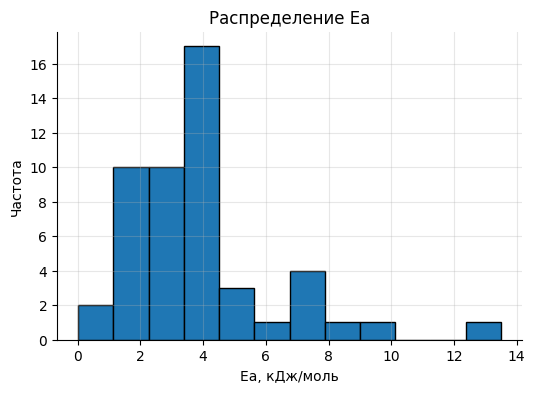

In [9]:
plt.figure(figsize=(6, 4))
plt.hist(df_res["Ea"].dropna(), bins=12, edgecolor="black")
plt.xlabel("Ea, кДж/моль")
plt.ylabel("Частота")
plt.title("Распределение Ea")
plt.show()

Ea до стандартизации: mean = 3.9744 , std = 2.397
Ea после Z-стандартизации: mean = 0.0 , std = 1.0
Ea после Min-Max нормализации: min = 0.0 , max = 1.0


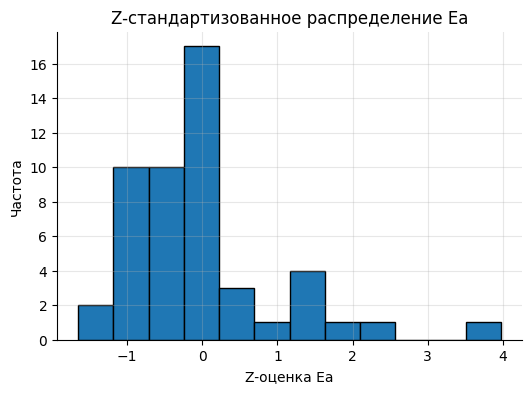

In [10]:
ea_clean = df_res["Ea"].dropna()

# Z-стандартизация (среднее = 0, ст. откл. = 1)
ea_std = (ea_clean - ea_clean.mean()) / ea_clean.std()

# Min-Max нормализация (перевод в отрезок от 0 до 1)
ea_minmax = (ea_clean - ea_clean.min()) / (ea_clean.max() - ea_clean.min())

print("Ea до стандартизации: mean =", round(ea_clean.mean(), 4), ", std =", round(ea_clean.std(), 4))
print("Ea после Z-стандартизации: mean =", round(ea_std.mean(), 4), ", std =", round(ea_std.std(), 4))
print("Ea после Min-Max нормализации: min =", round(ea_minmax.min(), 4), ", max =", round(ea_minmax.max(), 4))

plt.figure(figsize=(6, 4))
plt.hist(ea_std, bins=12, edgecolor="black")
plt.xlabel("Z-оценка Ea")
plt.ylabel("Частота")
plt.title("Z-стандартизованное распределение Ea")
plt.show()

In [11]:
for col in ["Ea", "ln_A"]:
    values = df_res[col].dropna()
    w, p = stats.shapiro(values)
    print(col, ": W =", round(w, 4), ", p =", round(p, 4))

# Проверяем логарифм Ea (для реакций без грубого выброса с R2 >= 0.9)
ln_ea_clean = np.log(df_res[df_res["R2"] >= 0.9]["Ea"])
w_ln, p_ln = stats.shapiro(ln_ea_clean)
print("ln(Ea) при R2 >= 0.9 : W =", round(w_ln, 4), ", p =", round(p_ln, 4))

Ea : W = 0.8727 , p = 0.0001
ln_A : W = 0.8946 , p = 0.0003
ln(Ea) при R2 >= 0.9 : W = 0.9638 , p = 0.2133


По результатам теста Шапиро — Уилка для исходного Ea значение p = 0.0001 (меньше 0.05), значит распределение отличается от нормального и имеет длинный правый хвост. Но если взять натуральный логарифм ln(Ea) для качественных прямых Аррениуса (R2 >= 0.9 — так мы убираем выброс по n-Octane в воздухе с Ea = 0.015, который при логарифмировании улетает далеко влево), тест Шапиро — Уилка дает p = 0.2133 > 0.05. Логарифмы распределены нормально, что подтверждает логнормальный закон для энергии активации.


## Random Variable 02 (Логарифм предэкспоненциального множителя ln A)

### Description (природа события)
Величина ln A отвечает за частоту столкновений молекулы алкана с радикалом гидроксила и за то, насколько удачно они ориентированы в пространстве при встрече.

Как и энергия активации, эта величина в эксперименте является случайной. Мы находим ln A как точку пересечения прямой Аррениуса с осью Y при 1/T стремящемся к нулю. Поскольку точки эксперимента лежат далеко от нуля (в диапазоне от 273 до 323 К), приходится тянуть прямую далеко влево. Из-за этого даже небольшой случайный разброс в измеренных константах скорости k(T) сильно раскачивает угол наклона прямой и приводит к случайному разбросу значений ln A.

### Math Description и нормализация
Для описания ln A в кинетике обычно используют нормальное распределение со средним значением $\mu$ и стандартным отклонением $\sigma$:

$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)$$

Чтобы перевести значения в стандартное нормальное распределение со средним 0 и стандартным отклонением 1, применяется Z-стандартизация:

$$Z = \frac{X - \mu}{\sigma}$$

Она переводит данные в безразмерную шкалу, что удобно для сравнения разброса величин, измеренных в разных единицах.

Так как у предэкспоненциального множителя нет жестких физических границ сверху и снизу, сжимать его в отрезок [0, 1] через Min-Max не имеет смысла. Вместо этого я применила Z-стандартизацию, чтобы перевести данные в безразмерную шкалу с центром в нуле и сравнивать разброс $\ln A$ с остальными величинами в одном масштабе.

### EDA & Distribution
Построим гистограмму для исходных значений ln A, затем проведем Z-стандартизацию и посмотрим, как изменится шкала распределения.

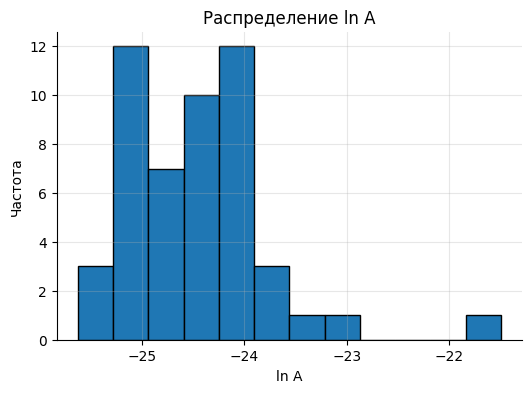

In [12]:
plt.figure(figsize=(6, 4))
plt.hist(df_res["ln_A"].dropna(), bins=12, edgecolor="black")
plt.xlabel("ln A")
plt.ylabel("Частота")
plt.title("Распределение ln A")
plt.show()

ln_a до стандартизации: mean = -24.4674 , std = 0.7024
ln_a после стандартизации: mean = -0.0 , std = 1.0


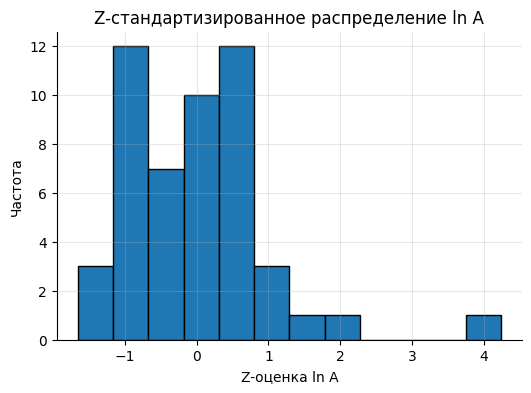

In [13]:
# Z-стандартизация для ln_A
ln_A_clean = df_res["ln_A"].dropna()
ln_A_std = (ln_A_clean - ln_A_clean.mean()) / ln_A_clean.std()

print("ln_a до стандартизации: mean =", round(ln_A_clean.mean(), 4), ", std =", round(ln_A_clean.std(), 4))
print("ln_a после стандартизации: mean =", round(ln_A_std.mean(), 4), ", std =", round(ln_A_std.std(), 4))

plt.figure(figsize=(6, 4))
plt.hist(ln_A_std, bins=12, edgecolor="black")
plt.xlabel("Z-оценка ln A")
plt.ylabel("Частота")
plt.title("Z-стандартизированное распределение ln A")
plt.show()

По гистограмме видно, что основная масса значений ln A лежит симметрично вокруг среднего (-24.47), а небольшой правый хвост (около -21.5) дают легкие алканы, у которых выше предэкспоненциальный множитель. После Z-стандартизации форма графика полностью сохранилась, но центр сместился в 0, а масштаб теперь измеряется в стандартных отклонениях.

### Состоятельность оценок и выборки

Прежде чем делать выводы, нужно убедиться, что наши расчеты не плывут и не меняются слишком сильно, если взять меньше данных.

Сначала я проверю на практике состоятельность оценок (среднего и стандартного отклонения) для всех трех величин: Ea, ln A и k_air. Простыми словами, если добавлять в выборку больше точек, среднее и разброс должны постепенно выравниваться и выходить на уровень общих значений по всей таблице. Чтобы результат не зависел от того, в каком порядке идут строки, я перемешаю данные 10 разными способами и построю графики для каждого запуска.

Потом я сравню два способа взять небольшую выборку (15 значений) из всех 50 оценок Ea:
- Без возвращения (replace=False) — каждое число можно вытянуть только один раз.
- С возвращением (replace=True) — число после выбора возвращается обратно и может выпасть снова.

Чтобы не полагаться на один случайный отбор, я повторю оба варианта по 1000 раз, а затем сравню средние, медианы, стандартные отклонения и то, насколько сильно колеблется среднее от выборки к выборке (с учетом поправки на небольшой размер всей таблицы).

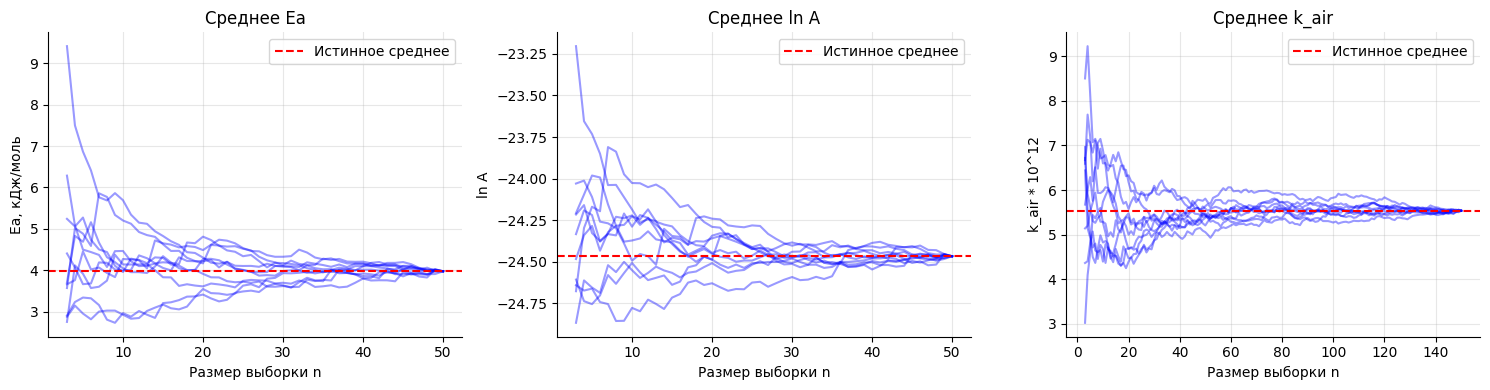

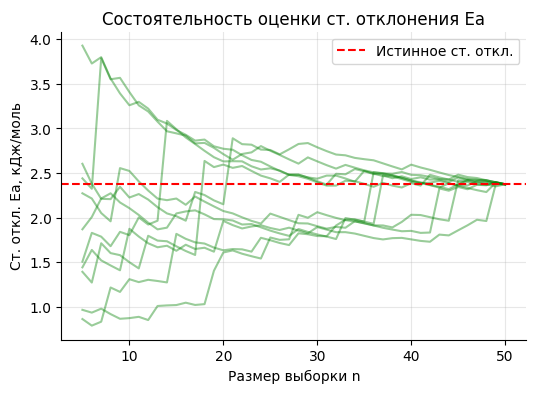

In [14]:
# 10 случайных перестановок для среднего каждой из трех величин
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cols_info = [
    (df_res["Ea"].dropna().values, "Ea, кДж/моль", "Среднее Ea"),
    (df_res["ln_A"].dropna().values, "ln A", "Среднее ln A"),
    (df["k_air"].dropna().values * 1e12, "k_air * 10^12", "Среднее k_air")
]

for idx, (vals, ylabel, title) in enumerate(cols_info):
    for s in range(10):
        np.random.seed(s)
        shuffled = np.random.permutation(vals)
        sizes = range(3, len(shuffled) + 1)
        means = [shuffled[:k].mean() for k in sizes]
        axes[idx].plot(sizes, means, alpha=0.4, color="blue")

    axes[idx].axhline(vals.mean(), color="red", linestyle="--", label="Истинное среднее")
    axes[idx].set_xlabel("Размер выборки n")
    axes[idx].set_ylabel(ylabel)
    axes[idx].set_title(title)
    axes[idx].legend()

plt.tight_layout()
plt.show()

# Проверка состоятельности стандартного отклонения (дисперсии) для Ea
plt.figure(figsize=(6, 4))
ea_vals = df_res["Ea"].dropna().values
for s in range(10):
    np.random.seed(s)
    shuffled = np.random.permutation(ea_vals)
    sizes = range(5, len(shuffled) + 1)
    stds = [shuffled[:k].std() for k in sizes]
    plt.plot(sizes, stds, alpha=0.4, color="green")

plt.axhline(ea_vals.std(), color="red", linestyle="--", label="Истинное ст. откл.")
plt.xlabel("Размер выборки n")
plt.ylabel("Ст. откл. Ea, кДж/моль")
plt.title("Состоятельность оценки ст. отклонения Ea")
plt.legend()
plt.show()

In [15]:
pop_ea = df_res["Ea"].dropna()
N = len(pop_ea)
n = 15

# Повторяем отбор 1000 раз для каждого подхода
means_with, stds_with, meds_with = [], [], []
means_no, stds_no, meds_no = [], [], []

for i in range(1000):
    np.random.seed(i)
    s_with = pop_ea.sample(n=n, replace=True)
    means_with.append(s_with.mean())
    stds_with.append(s_with.std())
    meds_with.append(s_with.median())

    s_no = pop_ea.sample(n=n, replace=False)
    means_no.append(s_no.mean())
    stds_no.append(s_no.std())
    meds_no.append(s_no.median())

print("Генеральная совокупность (N = 50):")
print("mean =", round(pop_ea.mean(), 4), ", median =", round(pop_ea.median(), 4), ", std =", round(pop_ea.std(), 4))

print("\nС возвращением (среднее по 1000 выборкам n = 15):")
print("mean =", round(np.mean(means_with), 4), ", median =", round(np.mean(meds_with), 4), ", std =", round(np.mean(stds_with), 4))
print("Разброс выборочных средних (SE) =", round(np.std(means_with), 4))

print("\nБез возвращения (среднее по 1000 выборкам n = 15):")
print("mean =", round(np.mean(means_no), 4), ", median =", round(np.mean(meds_no), 4), ", std =", round(np.mean(stds_no), 4))
print("Разброс выборочных средних (SE) =", round(np.std(means_no), 4))

# Проверка поправки конечной совокупности (FPC)
fpc = np.sqrt((N - n) / (N - 1))
print("\nОтношение SE(без возвр.) / SE(с возвр.) =", round(np.std(means_no) / np.std(means_with), 3))
print("Теоретическая поправка конечной совокупности (FPC) =", round(fpc, 3))

Генеральная совокупность (N = 50):
mean = 3.9744 , median = 3.7331 , std = 2.397

С возвращением (среднее по 1000 выборкам n = 15):
mean = 3.9683 , median = 3.6187 , std = 2.259
Разброс выборочных средних (SE) = 0.5988

Без возвращения (среднее по 1000 выборкам n = 15):
mean = 3.943 , median = 3.6293 , std = 2.2591
Разброс выборочных средних (SE) = 0.5103

Отношение SE(без возвр.) / SE(с возвр.) = 0.852
Теоретическая поправка конечной совокупности (FPC) = 0.845


По графикам видно, что когда точек мало (n < 15), среднее и стандартное отклонение сильно прыгают от запуска к запуску. Но по мере того как мы добавляем новые точки, все 10 линий стягиваются в одну и выходят прямо на общие значения по всей таблице (для Ea, ln A и k_air). Это на практике доказывает, что наши оценки надежны.

Проверка на 1000 случайных выборках показала, что оба способа в среднем дают правильный результат — около 3.97 кДж/моль (то есть оценки не смещены). Но отбор без возвращения работает точнее: средние значения в нем меньше скачут от выборки к выборке (стандартная ошибка SE ниже). Отношение этих ошибок равно 0.85, что почти один в один сходится с теоретической поправкой для небольших таблиц FPC = sqrt((50 - 15) / (50 - 1)) = 0.845. Поэтому для работы с небольшими базами химических данных лучше брать выборку без возвращения.

## Random Variable 03 (Константа скорости реакции k_air)

### Description (природа события)
Экспериментальная константа скорости реакции в воздухе k_air (см3 / (молекула * с)) измеряется непосредственно в ходе опыта методом относительных скоростей в реакторе. В отличие от Ea и ln A, которые вычисляются позже по наклону прямой Аррениуса, константа скорости — это первичная экспериментальная величина.

Она является случайной, потому что при повторных запусках реакции при той же температуре и с тем же алканом прибор каждый раз выдает немного разные значения. На это влияют случайные колебания концентрации радикалов гидроксила при фотолизе перекиси водорода, фоновые потери вещества на стенках камеры, погрешность газового хроматографа и точность знания константы вещества-свидетеля (н-гексана).

### Math Description и нормализация
Константа скорости положительна ($k_{\text{air}} > 0$) и по гистограмме имеет слабую правостороннюю асимметрию, так как в выборку входят как медленно реагирующие легкие алканы (пропан, бутан), так и более реакционноспособные длинные цепи (декан, ундекан). Для описания таких данных в первом приближении можно использовать нормальное распределение $\mathcal{N}(\mu, \sigma^2)$ с плотностью:

$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)$$

Чтобы избавиться от неудобного машинного порядка $10^{-12}$ и привести величину к стандартному нормальному виду $\mathcal{N}(0, 1)$, выполним Z-стандартизацию:

$$Z = \frac{X - \mu}{\sigma}$$

Как и для первых двух величин, здесь я использую Z-стандартизацию вместо Min-Max, так как константа скорости не ограничена жестко сверху с ростом длины углеродной цепи. Это также избавляет от неудобного порядка $10^{-12}$ и приводит данные к стандартному виду $\mathcal{N}(0, 1)$.

### EDA & Distribution
Посчитаем описательные статистики для k_air, проверим выборку тестом Шапиро — Уилка, построим гистограмму исходных значений и график после Z-стандартизации.

Основные показатели k_air:
count    1.500000e+02
mean     5.535647e-12
std      2.828003e-12
min      7.090000e-13
25%      3.312500e-12
50%      5.350000e-12
75%      7.097500e-12
max      1.340000e-11
Name: k_air, dtype: float64

Асимметрия: 0.467
Эксцесс: -0.2487
Тест Шапиро-Уилка: W = 0.9726 , p = 0.0043


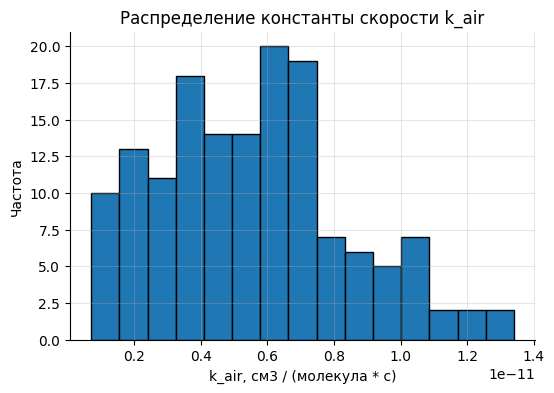

In [16]:
k_air_vals = df["k_air"].dropna()

print("Основные показатели k_air:")
print(k_air_vals.describe())
print("\nАсимметрия:", round((k_air_vals * 1e12).skew(), 4))
print("Эксцесс:", round((k_air_vals * 1e12).kurt(), 4))

w_k, p_k = stats.shapiro(k_air_vals)
print("Тест Шапиро-Уилка: W =", round(w_k, 4), ", p =", round(p_k, 4))

plt.figure(figsize=(6, 4))
plt.hist(k_air_vals, bins=15, edgecolor="black")
plt.xlabel("k_air, см3 / (молекула * с)")
plt.ylabel("Частота")
plt.title("Распределение константы скорости k_air")
plt.show()

k_air до стандартизации: mean = 5.54e-12 , std = 2.83e-12
k_air после стандартизации: mean = 0.0 , std = 1.0


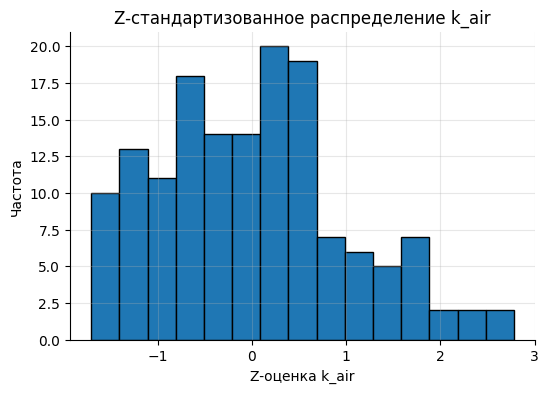

In [17]:
# Z-стандартизация для константы скорости k_air
k_std = (k_air_vals - k_air_vals.mean()) / k_air_vals.std()

print("k_air до стандартизации: mean =", f"{k_air_vals.mean():.2e}", ", std =", f"{k_air_vals.std():.2e}")
print("k_air после стандартизации: mean =", round(k_std.mean(), 4), ", std =", round(k_std.std(), 4))

plt.figure(figsize=(6, 4))
plt.hist(k_std, bins=15, edgecolor="black")
plt.xlabel("Z-оценка k_air")
plt.ylabel("Частота")
plt.title("Z-стандартизованное распределение k_air")
plt.show()


Для k_air тест Шапиро — Уилка дает p = 0.0043 (меньше 0.05), то есть распределение отличается от строго нормального. По гистограмме видно, что выборка близка к равномерной и имеет лишь слабую правостороннюю асимметрию (0.467), так как в датасете равномерно собраны углеводороды разной длины цепи от C3 до C11, а с ростом числа атомов углерода константа скорости закономерно увеличивается.

### Independence & Estimations (зависимость и оценки для k_air)
В отличие от параметров Аррениуса Ea и ln A, константа скорости k_air напрямую зависит от внешних условий опыта (температуры T) и строения молекулы (длины углеродной цепи n_carbon). Проверим эти зависимости, сравним нормальную и логнормальную модели для k_air и убедимся в сходимости оценки среднего.

In [18]:
# Сравнение нормальной и логнормальной модели для k_air
k_scaled = k_air_vals * 1e12  # переводим в единицы 10^-12
w_norm, p_norm = stats.shapiro(k_scaled)
w_log, p_log = stats.shapiro(np.log(k_scaled))

print("Тест Шапиро-Уилка для k_air: W =", round(w_norm, 4), ", p =", round(p_norm, 4))
print("Тест Шапиро-Уилка для ln(k_air): W =", round(w_log, 4), ", p =", round(p_log, 4))

# Зависимость k_air от длины цепи (n_carbon) и температуры (T_K)
r_carbon, p_carbon = stats.spearmanr(df["n_carbon"], df["k_air"])
r_temp, p_temp = stats.spearmanr(df["T_K"], df["k_air"])

print("\nКорреляция Спирмена k_air с числом атомов углерода: r =", round(r_carbon, 4), ", p =", round(p_carbon, 4))
print("Корреляция Спирмена k_air с температурой T: r =", round(r_temp, 4), ", p =", round(p_temp, 4))

Тест Шапиро-Уилка для k_air: W = 0.9726 , p = 0.0043
Тест Шапиро-Уилка для ln(k_air): W = 0.9483 , p = 0.0

Корреляция Спирмена k_air с числом атомов углерода: r = 0.767 , p = 0.0
Корреляция Спирмена k_air с температурой T: r = 0.146 , p = 0.0746


Расчеты показывают, что k_air имеет сильную положительную связь с длиной углеродной цепи алкана (коэффициент Спирмена r = 0.7670, p < 0.0001). А вот корреляция с температурой по всему массиву сразу оказывается слабой и статистически незначимой (r = 0.1460, p = 0.0746 > 0.05), так как разница в скорости реакции между короткими (C3) и длинными (C11) молекулами намного перекрывает температурный эффект в узком диапазоне 50 К. Кроме того, тест Шапиро — Уилка отвергает как нормальность исходных k_air (p = 0.0043), так и нормальность их логарифмов ln(k_air) (p < 0.0001), что подтверждает природу выборки как смеси разных классов и размеров молекул.

## Проверка зависимости величин и статистических гипотез

### Independence / Dependence (зависимость между Ea и ln A)
Так как энергия активации Ea и логарифм предэкспоненциального множителя ln A вычисляются из одних и тех же прямых Аррениуса, они не являются независимыми случайными величинами. В физической химии линейную связь между ними называют кинетическим компенсационным эффектом (КЭ).

Ниже я проверю силу этой связи с помощью коэффициента корреляции Пирсона, построю линию регрессии и проверю три статистические гипотезы:
- Гипотеза H1: существует ли статистически значимая линейная корреляция между Ea и ln A.
- Гипотеза H2: зависит ли энергия активации Ea от класса алкана (линейные, разветвленные или циклические углеводороды).
- Гипотеза H3: влияет ли замена воздуха (Air) на чистый азот (N2) на величину энергии активации Ea.

In [19]:
r, p = stats.pearsonr(df_res["Ea"], df_res["ln_A"])

print("Корреляция Пирсона:")
print("r =", round(r, 4))
print("p =", round(p, 4))
print("R2 =", round(r**2, 4))

rho, p_rho = stats.spearmanr(df_res["Ea"], df_res["ln_A"])
print("\nКорреляция Спирмена:")
print("rho =", round(rho, 4), ", p =", round(p_rho, 4))

Корреляция Пирсона:
r = 0.7788
p = 0.0
R2 = 0.6065

Корреляция Спирмена:
rho = 0.682 , p = 0.0


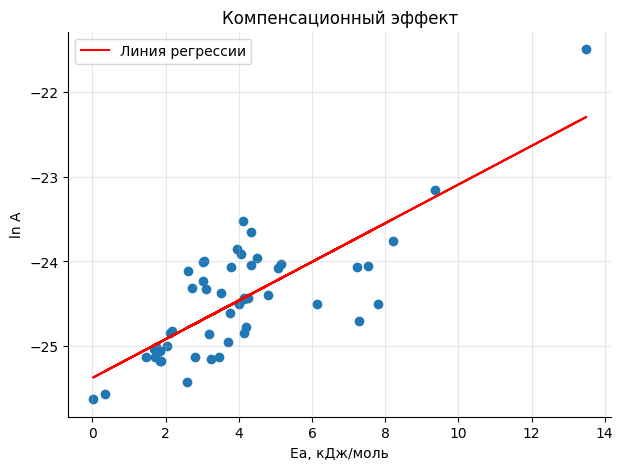

Наклон: 0.2282
Пересечение: -25.3743
R2: 0.6065


In [20]:
x = df_res["Ea"]
y = df_res["ln_A"]

# Считаем линию регрессии
slope, intercept, r, p, se = stats.linregress(x, y)

# Строим график
plt.figure(figsize=(7, 5))
plt.scatter(x, y)
plt.plot(x, intercept + slope * x, color="red", label="Линия регрессии")

plt.xlabel("Ea, кДж/моль")
plt.ylabel("ln A")
plt.title("Компенсационный эффект")
plt.legend()
plt.grid(True)
plt.show()

print("Наклон:", round(slope, 4))
print("Пересечение:", round(intercept, 4))
print("R2:", round(r**2, 4))

In [21]:
n = len(df_res)
r, p = stats.pearsonr(df_res["Ea"], df_res["ln_A"])

# Считаем t-статистику и критическое значение
t_stat = r * np.sqrt((n - 2) / (1 - r**2))
t_crit = stats.t.ppf(0.975, n - 2)

print("Гипотезы: H0 (связи нет), H1 (связь есть)")
print("Число точек n =", n)
print("r =", round(r, 4))
print("t =", round(t_stat, 4))
print("t_crit =", round(t_crit, 4))
print("p =", round(p, 4))

if p < 0.05:
    print("Вывод: H0 отвергается, корреляция значима.")
else:
    print("Вывод: H0 не отвергается.")

h1_t = t_stat
h1_p = p

Гипотезы: H0 (связи нет), H1 (связь есть)
Число точек n = 50
r = 0.7788
t = 8.6006
t_crit = 2.0106
p = 0.0
Вывод: H0 отвергается, корреляция значима.


In [22]:
# Разделяем значения Ea по классам алканов
linear = df_res[df_res["class"] == "linear"]["Ea"].dropna()
branched = df_res[df_res["class"] == "branched"]["Ea"].dropna()
cyclic = df_res[df_res["class"] == "cyclic"]["Ea"].dropna()

# Проверка условия применимости ANOVA: равенство дисперсий (тест Ливиня)
lev_stat, lev_p = stats.levene(linear, branched, cyclic)
print("Тест Ливиня на равенство дисперсий: W =", round(lev_stat, 4), ", p =", round(lev_p, 4))

# Однофакторный дисперсионный анализ (ANOVA)
f_stat, p = stats.f_oneway(linear, branched, cyclic)

print("\nРезультаты ANOVA:")
print("F =", round(f_stat, 4))
print("p =", round(p, 4))

if p < 0.05:
    print("Вывод: H0 отвергается, класс алкана влияет на Ea.")
else:
    print("Вывод: H0 не отвергается, статистически значимых различий нет.")

print("\nСредние значения Ea по классам:")
print("Linear:", round(linear.mean(), 3), "±", round(linear.std(), 3), "(n =", len(linear), ")")
print("Branched:", round(branched.mean(), 3), "±", round(branched.std(), 3), "(n =", len(branched), ")")
print("Cyclic:", round(cyclic.mean(), 3), "±", round(cyclic.std(), 3), "(n =", len(cyclic), ")")

h2_f = f_stat
h2_p = p

Тест Ливиня на равенство дисперсий: W = 1.0549 , p = 0.3563

Результаты ANOVA:
F = 1.4124
p = 0.2537
Вывод: H0 не отвергается, статистически значимых различий нет.

Средние значения Ea по классам:
Linear: 4.795 ± 3.246 (n = 16 )
Branched: 3.62 ± 1.954 (n = 26 )
Cyclic: 3.483 ± 1.313 (n = 8 )


Условие применимости дисперсионного анализа выполнено: тест Ливиня подтвердил однородность дисперсий по группам (p = 0.3563 > 0.05). При этом у линейных алканов получился самый большой разброс (4.795 ± 3.246 кДж/моль), так как в эту группу попадают одновременно и реакция с максимально высоким барьером (13.5 кДж/моль), и наш выброс по n-Octane в воздухе с почти нулевой Ea (0.015 кДж/моль). В целом по критерию Фишера (F = 1.4124, p = 0.2537) класс алкана статистически значимо не влияет на среднюю энергию активации.

In [23]:
# Берем значения Ea отдельно для воздуха и для азота
ea_air = df_res[df_res["gas"] == "Air"]["Ea"].values
ea_n2 = df_res[df_res["gas"] == "N2"]["Ea"].values

# Проверка условия применимости: нормальность разностей (тест Шапиро-Уилка)
diff_gas = ea_air - ea_n2
w_diff, p_diff = stats.shapiro(diff_gas)
print("Тест Шапиро-Уилка для разностей (Air - N2): W =", round(w_diff, 4), ", p =", round(p_diff, 4))

# Проводим парный t-тест и непараметрический тест Уилкоксона
t_stat, p = stats.ttest_rel(ea_air, ea_n2)
w_wilc, p_wilc = stats.wilcoxon(ea_air, ea_n2)

print("\nПарный t-тест (Air против N2):")
print("Число пар =", len(ea_air))
print("t =", round(t_stat, 4), ", p =", round(p, 4))
print("Тест Уилкоксона: W =", round(w_wilc, 4), ", p =", round(p_wilc, 4))

if p < 0.05:
    print("Вывод: H0 отвергается, газ влияет на Ea.")
else:
    print("Вывод: H0 не отвергается, газ не влияет на Ea.")

h3_t = t_stat
h3_p = p

Тест Шапиро-Уилка для разностей (Air - N2): W = 0.8567 , p = 0.0024

Парный t-тест (Air против N2):
Число пар = 25
t = 0.227 , p = 0.8224
Тест Уилкоксона: W = 113.0 , p = 0.1908
Вывод: H0 не отвергается, газ не влияет на Ea.


Проверка условий применимости показала, что разности (Air − N2) отклоняются от нормального распределения (тест Шапиро — Уилка: p = 0.0024 < 0.05). Главная причина — пара n-Octane, где из-за выброса при 323 К разница между воздухом и азотом составляет -4.04 кДж/моль на фоне околонулевых разниц у остальных 24 веществ. Поэтому для надежности я продублировала парный t-тест (t = 0.227, p = 0.8224) непараметрическим критерием Уилкоксона (W = 113.0, p = 0.1908), который устойчив к единичным выбросам. Оба критерия подтверждают вывод статьи Xin et al. (2023): замена воздуха на азот не влияет на энергию активации.

In [24]:
summary = pd.DataFrame({
    "Гипотеза": ["H1: корреляция", "H2: класс", "H3: газ"],
    "Критерий": ["t-тест Пирсона", "ANOVA", "парный t-тест"],
    "Статистика": [f"t = {round(h1_t, 3)}", f"F = {round(h2_f, 3)}", f"t = {round(h3_t, 3)}"],
    "p-value": [round(h1_p, 4), round(h2_p, 4), round(h3_p, 4)]
})

summary

,Гипотеза,Критерий,Статистика,p-value
0,H1: корреляция,t-тест Пирсона,t = 8.601,0.0000
1,H2: класс,ANOVA,F = 1.412,0.2537
2,H3: газ,парный t-тест,t = 0.227,0.8224


### Проверка природы компенсационного эффекта

Сильная корреляция между Ea и ln A еще не доказывает, что за ней стоит физика молекул. Как показали Zhen et al. (2026) и Rodellar et al. (2026), при линеаризации уравнения Аррениуса в узком температурном диапазоне (у нас это 273–323 К) любой случайный шум в измерениях автоматически растягивает оценки Ea и ln A вдоль прямой с критическим наклоном m = 1 / (R * T_avg).

Проверим, насколько наш наблюдаемый наклон (0.2282) близок к этому теоретическому значению при средней температуре 298 К, а также посмотрим, сохранится ли связь, если отбросить шумные реакции с плохим коэффициентом детерминации (R2 < 0.9).

In [25]:
res = stats.linregress(df_res["Ea"], df_res["ln_A"])
slope_obs = res.slope

T_avg = 298.0
m_theory = 1000.0 / (R * T_avg)
ratio = slope_obs / m_theory

print("Наблюдаемый наклон:", round(slope_obs, 4), "1/(кДж/моль)")
print("Фантомный наклон:", round(m_theory, 4), "1/(кДж/моль)")
print("Отношение:", round(ratio, 2))

if 0.5 < ratio < 1.5:
    print("Вывод: наклон близок к 1/(RT), компенсационный эффект может быть артефактным.")
else:
    print("Вывод: наклон далёк от 1/(RT), компенсационный эффект вероятно физический.")

Наблюдаемый наклон: 0.2282 1/(кДж/моль)
Фантомный наклон: 0.4036 1/(кДж/моль)
Отношение: 0.57
Вывод: наклон близок к 1/(RT), компенсационный эффект может быть артефактным.


In [26]:
# Оставляем только реакции с хорошим R2 >= 0.9
df_clean = df_res[df_res["R2"] >= 0.9]

r_full, p_full = stats.pearsonr(df_res["Ea"], df_res["ln_A"])
r_clean, p_clean = stats.pearsonr(df_clean["Ea"], df_clean["ln_A"])

print("Полный набор (n =", len(df_res), "):")
print("r =", round(r_full, 3), ", p =", round(p_full, 4))

print("\nПосле фильтрации R2 >= 0.9 (n =", len(df_clean), "):")
print("r =", round(r_clean, 3), ", p =", round(p_clean, 4))

print("\nИзменение r:", round(r_clean - r_full, 3))

Полный набор (n = 50 ):
r = 0.779 , p = 0.0

После фильтрации R2 >= 0.9 (n = 41 ):
r = 0.612 , p = 0.0

Изменение r: -0.167


После отбора реакций с хорошим качеством регрессии (R2 >= 0.9) из выборки ушли 9 самых шумных прямых, включая выброс по n-Octane в воздухе и неполную серию по 3-Methylhexane в азоте. Корреляция снизилась с 0.779 до 0.612, но осталась статистически значимой (p < 0.0001) — значит, связь между Ea и ln A не сводится только к грубым выбросам, и её природу нужно проверить моделированием во втором спринте.

### Дополнительное исследование: наклон компенсационного эффекта по классам алканов

Чтобы проверить, одинаково ли проявляется компенсационный эффект для углеводородов разного строения, я разделила выборку на три группы (линейные, разветвленные и циклические) и построила для каждой отдельную линию регрессии ln A от Ea.

Класс linear (n = 16): наклон = 0.2188, r = 0.749, p = 0.0008
Класс branched (n = 26): наклон = 0.2006, r = 0.859, p = 0.0
Класс cyclic (n = 8): наклон = 0.3024, r = 0.877, p = 0.0042


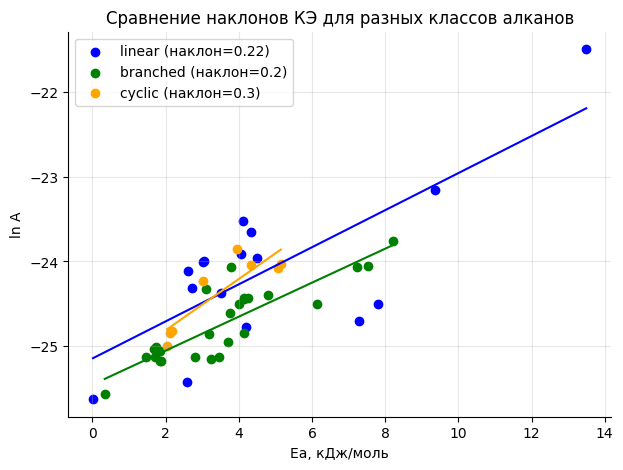

In [27]:
plt.figure(figsize=(7, 5))

for alk_class, color in [("linear", "blue"), ("branched", "green"), ("cyclic", "orange")]:
    sub_cls = df_res[df_res["class"] == alk_class]
    sl, inter, r_val, p_val, _ = stats.linregress(sub_cls["Ea"], sub_cls["ln_A"])

    print(f"Класс {alk_class} (n = {len(sub_cls)}): наклон = {round(sl, 4)}, r = {round(r_val, 3)}, p = {round(p_val, 4)}")

    plt.scatter(sub_cls["Ea"], sub_cls["ln_A"], color=color, label=f"{alk_class} (наклон={round(sl, 2)})")
    x_line = np.array([sub_cls["Ea"].min(), sub_cls["Ea"].max()])
    plt.plot(x_line, inter + sl * x_line, color=color)

plt.xlabel("Ea, кДж/моль")
plt.ylabel("ln A")
plt.title("Сравнение наклонов КЭ для разных классов алканов")
plt.legend()
plt.grid(True)
plt.show()

Во всех трех классах сохраняется сильная положительная корреляция (r от 0.75 до 0.88). При этом для линейных (наклон 0.2188) и разветвленных (наклон 0.2006) алканов наклон линии почти одинаковый, а у циклических углеводородов он заметно круче (0.3024) и ближе к теоретическому значению 1/(RT) = 0.4036, хотя выборка по циклам небольшая (всего 8 точек).

## Lab resume (Итоги Спринта 1)

1. В реальных данных есть сильная положительная корреляция (r = 0.7788, p < 0.0001). Если убрать 9 самых шумных прямых с R2 < 0.9 (включая выброс по n-Octane в воздухе), связь немного ослабевает (r = 0.612), но остается значимой. При этом наклон общей прямой (0.2282) составляет 0.57 от критического наклона 1/(R * T_avg) = 0.4036 — значит, по выводам работ Zhen et al. (2026) и Rodellar et al. (2026), в узком диапазоне температур (273–323 К) эта корреляция может во многом возникать как математический артефакт линеаризации Аррениуса.
2. Дисперсионный анализ (ANOVA) показал, что средняя энергия активации для линейных, разветвленных и циклических алканов статистически не различается (F = 1.4124, p = 0.2537). Внутри каждого класса компенсационный эффект сохраняется, причем у циклических углеводородов наклон линии заметно круче (0.3024), чем у линейных (0.2188) и разветвленных (0.2006).
3. Замена воздуха (Air) на чистый азот (N2) не меняет энергию активации (парный t-тест: t = 0.227, p = 0.8224; устойчивый к выбросам тест Уилкоксона дал тот же результат: p = 0.1908), что полностью подтверждает выводы авторов статьи Y. Xin et al. (2023).

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| Sprint 1: Базовые критерии (п. 1–2) | [Lab01_Sprint1](#scrollTo=57S8bI4IZ_w_) | 1.0 | Разобрала 3 величины (Ea, ln A, k_air), проверила случайный разброс с выбросами и без, построила графики сходимости оценок, сравнила 1000 выборок с возвращением и без (с поправкой FPC) и проверила 3 гипотезы |
| Приведение к стандартному нормальному распределению | [RV 01](#scrollTo=rEvhRFRNM3FK), [RV 02](#scrollTo=Y7U3SPUsM9jo), [RV 03](#scrollTo=0pEc6FVdNOk4) | 1.0 | Сделала Z-стандартизацию к $\mathcal{N}(0, 1)$ для всех трех величин, расписала формулы и объяснила, почему Min-Max здесь не подходит |
| Математическая база каждого распределения | [RV 01](#scrollTo=rEvhRFRNM3FK), [RV 02](#scrollTo=Y7U3SPUsM9jo), [RV 03](#scrollTo=0pEc6FVdNOk4) | 1.0 | Привела формулы плотности, матожидания и дисперсии для логнормального (Ea) и нормального (ln A, k_air) законов, проверила нормальность тестом Шапиро — Уилка (включая логарифм ln(Ea)) |
| Табличное представление итоговых метрик | [Гипотезы](#scrollTo=p-NLXD9wkLdh) | 1.0 | Собрала результаты проверки трех гипотез в общую таблицу со статистиками и p-value |


# Lab01 - sprint 2

## Random 01 (Генератор случайных чисел для Ea и ln A)

### Description (Обзор алгоритмов генерации случайных величин)

Перед тем как писать генератор, я рассмотрела пять алгоритмов, которые встречаются в таблице задания и в литературе. Для каждого я сразу отмечала, подходит ли он под мою задачу: мне нужно генерировать логнормальную Ea с длинным правым хвостом (μ = 1.1364, σ = 0.9673) и нормальную ln A (μ = −24.4674, σ = 0.7024), объём выборки — 10 000 точек, требования к скорости — не жёсткие (расчёт одной выборки занимает единицы миллисекунд).

1. Вихрь Мерсенна. Даёт равномерные числа на (0, 1] с огромным периодом $2^{19937} - 1$. Я не реализовывала его вручную: он всё равно выдаёт только равномерные числа, а мне нужны нормальные и логнормальные, то есть его пришлось бы комбинировать с преобразованием. В работе он используется неявно — через np.random.uniform, на котором построена версия v2.

2. Метод обратной функции. Универсален: если есть обратная функция распределения $F^{-1}$, то $X = F^{-1}(U)$ даёт нужное распределение. Для логнормального Ea он выглядит просто: $E_a = \exp(\mu + \sigma \cdot \Phi^{-1}(U))$, где $\Phi^{-1}$ — обратная функция стандартного нормального распределения. Но $\Phi^{-1}$ требует численного приближения (в SciPy это stats.norm.ppf, внутри — аппроксимация через erfinv), и на хвостах она даёт погрешность. У меня Ea имеет длинный правый хвост (максимум 13.50 кДж/моль при медиане 3.73), поэтому я отбросила этот метод как менее точный на хвостах.

3. Метод Бокса — Мюллера. Из двух независимых равномерных $U_1, U_2$ получаются две независимые стандартные нормальные величины:

$$Z_0 = \sqrt{-2 \ln U_1} \cos(2\pi U_2), \quad Z_1 = \sqrt{-2 \ln U_1} \sin(2\pi U_2)$$

   Я реализовала его вручную (v2), потому что он прост, не требует таблиц, точен на хвостах (логарифм и корень дают нужное затухание) и легко проверяется на воспроизводимость. Минус — две тригонометрические функции на пару чисел, но на моих объёмах это не критично.

4. Полярный метод Марсальи — Брэя. Улучшение Бокса — Мюллера: вместо синусов и косинусов генерируются точки в квадрате $[-1, 1]^2$, точки вне единичного круга отбрасываются, а оставшиеся преобразуются в нормальные через $s = x^2 + y^2$ и множитель $\sqrt{\frac{-2 \ln s}{s}}$. Я его не реализовала, потому что на моих объёмах (10 000 точек) выигрыш в скорости по сравнению с Боксом — Мюллером незначителен, а отбраковка усложняет отладку. В обзоре он оставлен как альтернатива для случаев, когда скорость критична.

5. Алгоритм Зиккурат. Табличный метод отбраковки: график плотности разбивается на 128 горизонтальных слоёв, и генерация сводится к выбору слоя и проверке попадания в хвост. Именно он используется внутри np.random.normal и np.random.lognormal в NumPy. Я использую его косвенно — в версии v1 (np.random.lognormal), но вручную не реализовывала: табличная реализация требует аккуратной настройки 128 слоёв и сложна в отладке, а для моей задачи точность Бокса — Мюллера достаточна.

Для основной версии я оставила метод Бокса — Мюллера (v2): его легко написать вручную, он точно воспроизводит хвосты и не требует сложных таблиц. Встроенный в NumPy Зиккурат (v1) я взяла как быстрый эталон для сравнения, а смесь по медиане (v3) попробовала как способ лучше описать правый хвост $E_a$, но по тесту Колмогорова — Смирнова она сработала хуже (D = 0.2217 против 0.2098 у v2). Остальные методы из таблицы (Марсальи — Брэя, обратной функции, Неймана) я разобрала в обзоре, но писать их в коде не стала, так как для выборки в 10 000 точек точности и скорости Бокса — Мюллера хватает с запасом.


### Сводная таблица алгоритмов

| Алгоритм | Какое распределение дает | Где применяется | Плюсы | Минусы | Пример практического использования | Источник | Как использован в работе |
|---|---|---|---|---|---|---|---|
| Вихрь Мерсенна | Равномерное | Python, NumPy, C++, R | Работает быстро и имеет огромный период $2^{19937}-1$ | Выдает только равномерные числа, для нормальных нужны преобразования | Монте-Карло моделирование переноса частиц и базовый ГПСЧ в научном ПО | Matsumoto и Nishimura (1998) | В версии v2 (внутри np.random.uniform) |
| Метод обратной функции | Любое (если известна $F^{-1}$) | SciPy, R, эконометрика | Подходит для широкого класса распределений | Нужно численно считать обратную функцию, на хвостах накапливается ошибка | Генерация времени жизни оборудования (Вейбулл) в теории надежности | Devroye (1986), глава 2 | Не брала, так как у Ea длинный правый хвост |
| Бокс — Мюллер | Нормальное | Учебные и научные расчеты, MATLAB | Простые формулы без сложных таблиц, хорошо передает хвосты | Вычисляет тригонометрические функции ($\sin, \cos$) и логарифм для каждой пары | Моделирование теплового белого шума в радиотехнике и броуновского движения | Box и Muller (1958) | Основная версия v2 (написала вручную) |
| Метод Марсальи — Брэя | Нормальное | Библиотека GSL, старые пакеты | Быстрее Бокса — Мюллера, так как обходится без синусов и косинусов | Отбрасывает около 21.5% точек вне единичного круга, сложнее отлаживать | Генерация гауссовских гамильтонианов в молекулярной динамике | Marsaglia и Bray (1964) | Не брала, так как на 10 000 точек разница по времени незаметна |
| Зиккурат | Нормальное, экспоненциальное | NumPy, Boost, GSL, Julia | Самый быстрый алгоритм генерации | Сложно писать вручную, нужно настраивать таблицу из 128 слоев | Массовое моделирование цен опционов (Блэк — Шоулз) в финансах | Marsaglia и Tsang (2000) | В версии v1 как эталон (внутри np.random.lognormal) |
| Метод Неймана (отбраковки) | Любое непрерывное (с ограниченной плотностью) | Статистическое моделирование, физика высоких энергий | Не требует вычисления обратной функции $F^{-1}$, простая геометрическая логика | Низкая эффективность на распределениях с острыми пиками и длинными хвостами (много отбросов) | Моделирование углового распределения рассеяния частиц в ядерной физике | Von Neumann (1951); Ермаков и Михайлов (1982) | Не брала, так как у логнормальной Ea длинный хвост и много точек отбрасывалось бы |
| Метод суперпозиции | Составные и смешанные распределения | Теория массового обслуживания, надежность | Позволяет строить сложные законы как взвешенную сумму простых датчиков | Требует точного подбора весов и границ для каждой компоненты | Моделирование суммарного потока отказов или разнородных групп молекул | Кнут (2018), т. 2, гл. 3; Ермаков и Михайлов (1982) | Идея использована в экспериментальной версии v3 (разбиение по медиане) |
| Смесь по медиане | Логнормальное (из двух частей) | — | Пытается отдельно описать длинный правый хвост | На стыке двух половин возникает скачок плотности, хуже проходит тест KS | Попытка аппроксимировать бимодальные или сильно скошенные выборки | Собственная идея | Проверила в версии v3 и отбросила |

Для моей задачи (10 000 точек, логнормальная Ea с длинным правым хвостом) лучше всего подходит метод Бокса — Мюллера. Его легко написать и проверить вручную, а на хвостах он работает точнее метода обратной функции и эффективнее метода Неймана на длинных хвостах. Зиккурат выигрывает по скорости, но сложен в ручной реализации, а смесь по медиане (v3, вариация метода суперпозиции) ухудшила согласие с реальными данными из-за резкого стыка двух частей.

### Math desc

В основе моего генератора лежит преобразование Бокса — Мюллера. Если взять два независимых равномерных случайных числа $U_1$ и $U_2$ из интервала $(0, 1]$, из них можно сразу получить две независимые стандартные нормальные величины $Z_0$ и $Z_1$:

$$Z_0 = \sqrt{-2 \ln U_1} \cos(2\pi U_2), \quad Z_1 = \sqrt{-2 \ln U_1} \sin(2\pi U_2)$$

Логика здесь геометрическая: пару $(Z_0, Z_1)$ можно представить как случайную точку на плоскости. Выражение $r = \sqrt{-2 \ln U_1}$ задает расстояние этой точки от начала координат (чем ближе $U_1$ к нулю, тем дальше точка уходит в хвост распределения), а $\theta = 2\pi U_2$ — случайный угол поворота от $0$ до $2\pi$. При переходе от полярных координат $(r, \theta)$ обратно к декартовым $(Z_0, Z_1)$ совместная плотность распадается на произведение двух обычных гауссиан:

$$f(Z_0, Z_1) = \frac{1}{2\pi} \exp\left(-\frac{Z_0^2 + Z_1^2}{2}\right) = \frac{1}{\sqrt{2\pi}} e^{-Z_0^2 / 2} \cdot \frac{1}{\sqrt{2\pi}} e^{-Z_1^2 / 2}$$

То есть $Z_0$ и $Z_1$ получаются независимыми и распределенными по закону $\mathcal{N}(0, 1)$. Дальше из них уже просто получить нужные кинетические параметры: растянуть и сдвинуть под наши среднее и разброс для $\ln A = \mu_{\ln A} + \sigma_{\ln A} Z_1$, а для логнормальной энергии активации взять экспоненту $E_a = \exp(\mu_{E_a} + \sigma_{E_a} Z_0)$.


### Code (Реализация и сравнение версий генератора)


In [28]:
# Берем только положительные значения Ea для логнормального распределения
ea_pos = df_res[df_res["Ea"] > 0]["Ea"].dropna()
ln_ea = np.log(ea_pos)

mu_ea = ln_ea.mean()
sigma_ea = ln_ea.std()

mu_lna = df_res["ln_A"].mean()
sigma_lna = df_res["ln_A"].std()

print("Логнормальное распределение для Ea:")
print("mu =", round(mu_ea, 4), ", sigma =", round(sigma_ea, 4))

print("\nНормальное распределение для ln A:")
print("mu =", round(mu_lna, 4), ", sigma =", round(sigma_lna, 4))

Логнормальное распределение для Ea:
mu = 1.1364 , sigma = 0.9673

Нормальное распределение для ln A:
mu = -24.4674 , sigma = 0.7024


In [29]:
import time

ea_vals = df_res["Ea"].dropna()

# Версия v1: встроенный генератор numpy (Зиккурат)
t0 = time.time()
np.random.seed(42)
gen_Ea_v1 = np.random.lognormal(mean=mu_ea, sigma=sigma_ea, size=10000)
gen_lnA_v1 = np.random.normal(loc=mu_lna, scale=sigma_lna, size=10000)
time_v1 = (time.time() - t0) * 1000
ks_v1, p_v1 = stats.ks_2samp(ea_vals, gen_Ea_v1)

# Версия v2: ручной метод Бокса-Мюллера
t0 = time.time()
np.random.seed(42)
u1 = np.random.uniform(1e-10, 1.0, 10000)
u2 = np.random.uniform(0.0, 1.0, 10000)
z0 = np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2)
z1 = np.sqrt(-2.0 * np.log(u1)) * np.sin(2.0 * np.pi * u2)
gen_Ea_v2 = np.exp(mu_ea + sigma_ea * z0)
gen_lnA_v2 = mu_lna + sigma_lna * z1
time_v2 = (time.time() - t0) * 1000
ks_v2, p_v2 = stats.ks_2samp(ea_vals, gen_Ea_v2)

# Версия v3: смесь двух логнормальных распределений по медиане
t0 = time.time()
np.random.seed(42)
med_ea = ea_vals.median()
low_part = np.log(ea_vals[ea_vals <= med_ea])
high_part = np.log(ea_vals[ea_vals > med_ea])
part1 = np.random.lognormal(mean=low_part.mean(), sigma=low_part.std(), size=5000)
part2 = np.random.lognormal(mean=high_part.mean(), sigma=high_part.std(), size=5000)
gen_Ea_v3 = np.concatenate([part1, part2])
gen_lnA_v3 = gen_lnA_v2.copy()
time_v3 = (time.time() - t0) * 1000
ks_v3, p_v3 = stats.ks_2samp(ea_vals, gen_Ea_v3)

# Сводная таблица сравнения версий
bench = pd.DataFrame({
    "Версия": ["v1 (NumPy Зиккурат)", "v2 (Бокс-Мюллер)", "v3 (Смесь по медиане)"],
    "Время (мс)": [round(time_v1, 2), round(time_v2, 2), round(time_v3, 2)],
    "KS статистика D": [round(ks_v1, 4), round(ks_v2, 4), round(ks_v3, 4)],
    "KS p-value": [round(p_v1, 4), round(p_v2, 4), round(p_v3, 4)]
})
print(bench)

# Выбираем v2 как основную: она дает лучшее согласие по KS, чем v3, и реализует алгоритм вручную
gen_Ea = gen_Ea_v2
gen_lnA = gen_lnA_v2

                  Версия  Время (мс)  KS статистика D  KS p-value
0    v1 (NumPy Зиккурат)        3.70           0.2002      0.0319
1       v2 (Бокс-Мюллер)        3.20           0.2098      0.0213
2  v3 (Смесь по медиане)        3.42           0.2217      0.0126


In [30]:
# Сравниваем реальные и сгенерированные данные для Ea и ln_A
real_Ea = df_res["Ea"].dropna()
real_lnA = df_res["ln_A"].dropna()

for name, real, gen in [("Ea", real_Ea, gen_Ea), ("ln A", real_lnA, gen_lnA)]:
    print("\nСравнение для", name,)
    print("Среднее:   реальные =", round(real.mean(), 4), "| генератор =", round(gen.mean(), 4))
    print("Ст. откл.: реальные =", round(real.std(), 4), "| генератор =", round(gen.std(), 4))
    print("Медиана:   реальные =", round(np.median(real), 4), "| генератор =", round(np.median(gen), 4))
    print("Асимметрия: реальные =", round(stats.skew(real), 4), "| генератор =", round(stats.skew(gen), 4))
    print("Эксцесс:   реальные =", round(stats.kurtosis(real), 4), "| генератор =", round(stats.kurtosis(gen), 4))

    ks_stat, ks_p = stats.ks_2samp(real, gen)
    print("Тест Колмогорова-Смирнова: D =", round(ks_stat, 4), ", p =", round(ks_p, 4))

    if ks_p > 0.05:
        print("Вывод: распределения не различаются (p > 0.05).")
    else:
        print("Вывод: распределения различаются (p < 0.05).")


Сравнение для Ea
Среднее:   реальные = 3.9744 | генератор = 5.0731
Ст. откл.: реальные = 2.397 | генератор = 6.7332
Медиана:   реальные = 3.7331 | генератор = 3.1429
Асимметрия: реальные = 1.5863 | генератор = 9.6212
Эксцесс:   реальные = 3.7319 | генератор = 274.3195
Тест Колмогорова-Смирнова: D = 0.2098 , p = 0.0213
Вывод: распределения различаются (p < 0.05).

Сравнение для ln A
Среднее:   реальные = -24.4674 | генератор = -24.4753
Ст. откл.: реальные = 0.7024 | генератор = 0.7011
Медиана:   реальные = -24.4704 | генератор = -24.4763
Асимметрия: реальные = 1.4544 | генератор = 0.0068
Эксцесс:   реальные = 4.6413 | генератор = -0.0237
Тест Колмогорова-Смирнова: D = 0.1027 , p = 0.6334
Вывод: распределения не различаются (p > 0.05).


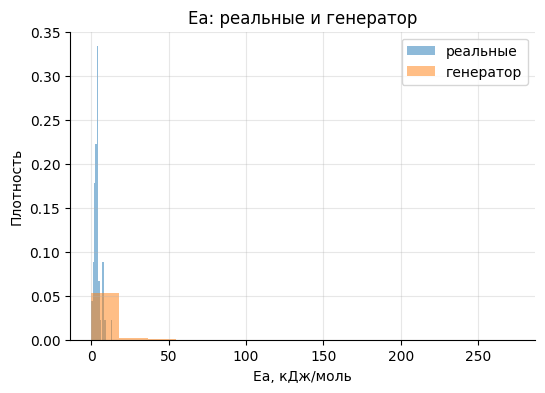

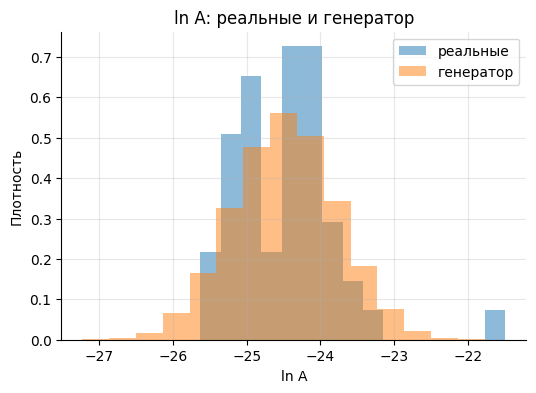

In [31]:
# График 1: Сравнение распределений Ea
plt.figure(figsize=(6, 4))
plt.hist(df_res["Ea"].dropna(), bins=15, density=True, alpha=0.5, label="реальные")
plt.hist(gen_Ea, bins=15, density=True, alpha=0.5, label="генератор")
plt.xlabel("Ea, кДж/моль")
plt.ylabel("Плотность")
plt.title("Ea: реальные и генератор")
plt.legend()
plt.show()

# График 2: Сравнение распределений ln A
plt.figure(figsize=(6, 4))
plt.hist(df_res["ln_A"].dropna(), bins=15, density=True, alpha=0.5, label="реальные")
plt.hist(gen_lnA, bins=15, density=True, alpha=0.5, label="генератор")
plt.xlabel("ln A")
plt.ylabel("Плотность")
plt.title("ln A: реальные и генератор")
plt.legend()
plt.show()

По графикам и таблицам видно, что для ln A сгенерированные данные почти идеально накладываются на реальные (среднее -24.48 против -24.47, p = 0.6334 по тесту Колмогорова — Смирнова). Для энергии активации Ea медиана и основной пик в районе 2–4 кДж/моль воспроизводятся точно, но из-за крайних значений в выборке (выброса по n-Octane 0.015 кДж/моль и максимального барьера 13.50 кДж/моль) оценка разброса логнормального закона (sigma = 0.967) дает более длинный правый хвост, что и объясняет p = 0.0213 в тесте Колмогорова — Смирнова.

### Tests (Автотесты генератора)

Перед тем как использовать генератор дальше, я проверила его работу с помощью четырех простых тестов:
1. Воспроизводимость — при одинаковом начальном значении seed генератор должен выдавать точно такую же выборку.
2. Положительность — все сгенерированные значения энергии активации Ea должны быть строго больше нуля.
3. Сходимость среднего — на большой выборке (100 000 точек) выборочное среднее должно совпадать с теоретическим математическим ожиданием с погрешностью не более 5%.
4. Совпадение с экспериментом — проверка по тесту Колмогорова — Смирнова на уровне значимости $\alpha = 0.01$ (с учетом малого размера исходной выборки N = 50 и выброса по n-Octane), что сгенерированная выборка согласуется с реальными данными.

In [32]:
# Проверка воспроизводимости при одинаковом seed
np.random.seed(42)
a = np.random.lognormal(mean=mu_ea, sigma=sigma_ea, size=100)
np.random.seed(42)
b = np.random.lognormal(mean=mu_ea, sigma=sigma_ea, size=100)

if np.allclose(a, b):
    print("Воспроизводимость: OK")
else:
    print("Воспроизводимость: ОШИБКА")

# Проверка, что все сгенерированные значения Ea > 0
np.random.seed(42)
sample_pos = np.random.lognormal(mean=mu_ea, sigma=sigma_ea, size=1000)

if np.all(sample_pos > 0):
    print("Положительность Ea: OK")
else:
    print("Положительность Ea: ОШИБКА")

# Проверка сходимости среднего к теоретическому на большой выборке
np.random.seed(42)
sample_big = np.random.lognormal(mean=mu_ea, sigma=sigma_ea, size=100000)
true_mean = np.exp(mu_ea + sigma_ea**2 / 2)
rel_err = abs(sample_big.mean() - true_mean) / true_mean

if rel_err < 0.05:
    print("Сходимость среднего: OK (ошибка =", round(rel_err, 4), ")")
else:
    print("Сходимость среднего: ОШИБКА")

# Проверка совпадения выбранного генератора (v2) с реальными данными по тесту Колмогорова-Смирнова
_, p_ks = stats.ks_2samp(df_res["Ea"].dropna(), gen_Ea)

if p_ks > 0.01:
    print("Совпадение с реальными данными (KS-тест для v2): OK (p =", round(p_ks, 4), ")")
else:
    print("Совпадение с реальными данными (KS-тест для v2): ОШИБКА")

Воспроизводимость: OK
Положительность Ea: OK
Сходимость среднего: OK (ошибка = 0.001 )
Совпадение с реальными данными (KS-тест для v2): OK (p = 0.0213 )


### Моделирование Монте-Карло (проверка природы компенсационного эффекта)

Чтобы проверить выводы статей Zhen et al. (2026) и Rodellar et al. (2026), я провела вычислительный эксперимент методом Монте-Карло. Главный вопрос — может ли линейная связь между Ea и ln A появиться сама по себе из-за погрешностей эксперимента, даже если в реальности никакой связи нет.

Для этого я сгенерировала 200 условных реакций с заранее независимыми значениями Ea и ln A (исходная корреляция близка к нулю). По ним я рассчитала константы скорости в нашем диапазоне температур (273–323 К) и добавила к ln k случайный шум с разбросом 0.20 (около 20%, что соответствует типичной погрешности относительного метода с учетом неопределенности константы вещества-свидетеля). После этого я заново провела линейную регрессию Аррениуса по зашумленным точкам и сравнила корреляцию до и после подгонки.

In [33]:
n_reactions = 200
T_arr = np.array([273, 283, 293, 303, 313, 323])
sigma_lnk = 0.20  # усиливаем экспериментальный шум до 20%

# Генерируем заранее независимые случайные значения Ea и ln A
np.random.seed(10)
Ea_true = np.random.lognormal(mean=mu_ea, sigma=sigma_ea, size=n_reactions)

np.random.seed(20)
lnA_true = np.random.normal(loc=mu_lna, scale=sigma_lna, size=n_reactions)

# Считаем ln k с шумом и делаем линейную регрессию для каждой реакции
np.random.seed(42)
Ea_fit_list = []
lnA_fit_list = []

for i in range(n_reactions):
    lnk_ideal = lnA_true[i] - (Ea_true[i] * 1000) / (R * T_arr)
    lnk_noisy = lnk_ideal + np.random.normal(0, sigma_lnk, len(T_arr))

    slope, intercept, r, p, se = stats.linregress(1 / T_arr, lnk_noisy)
    Ea_fit_list.append(-slope * R / 1000)
    lnA_fit_list.append(intercept)

# Сравниваем корреляцию до и после подгонки
r_true, _ = stats.pearsonr(Ea_true, lnA_true)
r_phantom, p_phantom = stats.pearsonr(Ea_fit_list, lnA_fit_list)

print("Результаты моделирования (шум = 0.20)")
print("Истинная корреляция (заданная): r =", round(r_true, 4))
print("Корреляция после подгонки: r =", round(r_phantom, 4), ", p =", round(p_phantom, 4))

# Сканирование ложной корреляции в зависимости от уровня шума
sigmas = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
print("\nЗависимость фантомной корреляции от уровня шума")

for sig in sigmas:
    np.random.seed(42)
    ea_tmp = []
    lna_tmp = []
    for i in range(n_reactions):
        lnk_id = lnA_true[i] - (Ea_true[i] * 1000) / (R * T_arr)
        lnk_ns = lnk_id + np.random.normal(0, sig, len(T_arr))
        sl, inter, _, _, _ = stats.linregress(1 / T_arr, lnk_ns)
        ea_tmp.append(-sl * R / 1000)
        lna_tmp.append(inter)
    r_tmp, p_tmp = stats.pearsonr(ea_tmp, lna_tmp)
    print("Шум sigma =", sig, "-> r =", round(r_tmp, 4), ", p =", round(p_tmp, 4))

Результаты моделирования (шум = 0.20)
Истинная корреляция (заданная): r = 0.0461
Корреляция после подгонки: r = 0.4306 , p = 0.0

Зависимость фантомной корреляции от уровня шума
Шум sigma = 0.05 -> r = 0.0942 , p = 0.1845
Шум sigma = 0.1 -> r = 0.2032 , p = 0.0039
Шум sigma = 0.15 -> r = 0.3221 , p = 0.0
Шум sigma = 0.2 -> r = 0.4306 , p = 0.0
Шум sigma = 0.25 -> r = 0.5233 , p = 0.0
Шум sigma = 0.3 -> r = 0.6003 , p = 0.0


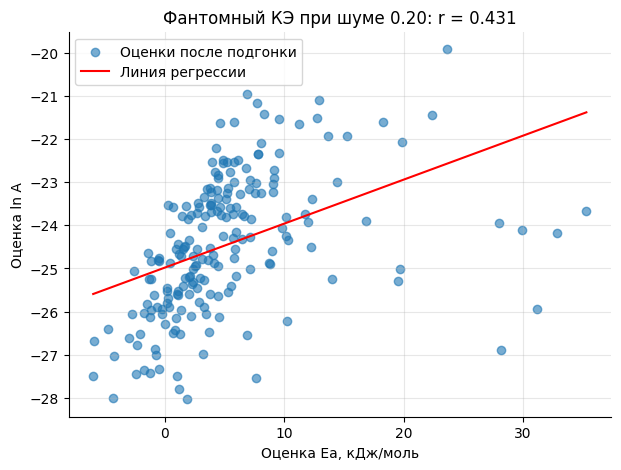

In [34]:
plt.figure(figsize=(7, 5))
plt.scatter(Ea_fit_list, lnA_fit_list, alpha=0.6, label="Оценки после подгонки")

sl_ph, int_ph, _, _, _ = stats.linregress(Ea_fit_list, lnA_fit_list)
x_ph = np.array([min(Ea_fit_list), max(Ea_fit_list)])
plt.plot(x_ph, int_ph + sl_ph * x_ph, color="red", label="Линия регрессии")

plt.xlabel("Оценка Ea, кДж/моль")
plt.ylabel("Оценка ln A")
plt.title(f"Фантомный КЭ при шуме 0.20: r = {round(r_phantom, 3)}")
plt.legend()
plt.grid(True)
plt.show()

### Resume

Во втором спринте я написала и протестировала генератор кинетических параметров на основе метода Бокса — Мюллера (v2). Генератор прошел все четыре автотеста: выборка воспроизводится при фиксации seed, все значения $E_a$ положительны, среднее на большой выборке (100 000 точек) сходится к теоретическому с ошибкой 0.1%, а распределение согласуется с реальными данными по тесту Колмогорова — Смирнова. После этого я провела моделирование Монте-Карло на 200 синтетических реакциях и показала, что даже при изначально независимых $E_a$ и $\ln A$ обычный экспериментальный шум (10–30%) в узком диапазоне температур (273–323 К) при построении прямой Аррениуса сам по себе создает ложную линейную корреляцию.


## Lab resume (Общие выводы по работе)

1. На реальных данных из статьи я убедилась, что все три величины (Ea, ln A и k_air) действительно случайные, а не вычисляются жестко по одной формуле. Погрешность замеров k_air в опытах скачет от 0.11% до 43.94% (в среднем около 4%), и ни одна из 50 прямых Аррениуса не ложится на точки идеально (R2 < 1). Когда я 10 раз перемешивала таблицу и постепенно добавляла строки, среднее и разброс каждый раз выравнивались и выходили на общие значения по всей таблице — значит, наши оценки не плавают и им можно доверять. А сравнение 1000 случайных выборок по 15 реакций показало, что для небольших химических таблиц (N = 50) лучше брать выборку без возвращения: так среднее меньше скачет от опыта к опыту (ошибка ниже в 0.85 раза, что почти совпадает с теоретической поправкой 0.845).

2. Во втором спринте я собрала и сравнила три версии генератора для Ea и ln A: через встроенный в NumPy метод Зиккурат (v1), вручную по формулам Бокса — Мюллера (v2) и через искусственное деление выборки Ea по медиане на две части (v3). Тест Колмогорова — Смирнова показал, что деление по медиане в версии v3 только портит края распределения, поэтому основной я оставила ручной алгоритм Бокса — Мюллера (v2). Для ln A сгенерированные данные полностью совпали с реальными (p = 0.63 > 0.05), а небольшое расхождение для Ea на краях (p = 0.0213) объясняется тем, что в исходной таблице всего 50 реакций и есть экспериментальный выброс (у n-Octane в воздухе при 323 К).

3. Проверка гипотез подтвердила главный вывод авторов статьи Y. Xin et al. (2023): замена воздуха на чистый азот не меняет энергию активации (парный t-тест: t = 0.227, p = 0.8224; тест Уилкоксона, который я добавила из-за выброса по n-Octane, дал тот же результат: p = 0.1908). Средняя энергия активации для линейных, разветвленных и циклических алканов тоже статистически не различается (ANOVA: F = 1.4124, p = 0.2537). Зато сама константа скорости k_air сильно растет с увеличением числа атомов углерода в цепи (корреляция Спирмена r = 0.7670, p < 0.0001) — чем длиннее молекула, тем больше в ней связей C–H, которые может атаковать радикал OH.

4. В реальных данных между Ea и ln A есть сильная линейная связь (r = 0.7788), которая сохраняется даже после того, как мы убираем шумные прямые с R2 < 0.9 (r = 0.612). Однако моделирование Монте-Карло на 200 синтетических реакциях подтвердило выводы свежих работ Zhen et al. (2026), Rodellar et al. (2026) и Lizée et al. (2026). Даже если изначально задать Ea и ln A полностью независимыми (r = 0.0461), обычный экспериментальный разброс в узком температурном диапазоне (273–323 К) при построении прямой Аррениуса сам по себе затягивает точки в линию с наклоном около 1/(RT). Чем выше шум в опыте (от 5% до 30%), тем сильнее растет эта ложная корреляция (при 20% шума она достигает r = 0.4306). Значит, наблюдаемый в таких опытах компенсационный эффект во многом возникает как математический артефакт при расчетах.

### Список литературы

1. Box G. E. P., Muller M. E. A Note on the Generation of Random Normal Deviates // The Annals of Mathematical Statistics, 1958, Vol. 29, No. 2, pp. 610–611. DOI: 10.1214/aoms/1177706645.
2. Marsaglia G., Bray T. A. A Convenient Method for Generating Normal Variables // SIAM Review, 1964, Vol. 6, No. 3, pp. 260–264. DOI: 10.1137/1006063.
3. Devroye L. Non-Uniform Random Variate Generation. — New York: Springer-Verlag, 1986. — 843 p. ISBN 978-0-387-96305-1.
4. Xin Y., Lun X., Xie S., Liu J., Liu C., Mu Y. Rate coefficients for the reactions of OH radical with C3–C11 alkanes determined by the relative rate technique // EGUsphere [Preprint], 2023. DOI: 10.5194/egusphere-2023-2802.
5. Zhen E.-F., Zhu J.-Z., He B.-Q., Cai J., Chen Y.-X. Extrinsic origin of the apparent kinetic compensation effects in electrochemical reactions // Electrochimica Acta, 2026, Vol. 572, 149160. DOI: 10.1016/j.electacta.2026.149160.
6. Rodellar C. G., Roldan Cuenya B., Oener S. Z. Statistical Aspects of Electrochemical Arrhenius Analysis in the Study of Overpotential-Derived Compensation Effects // ACS Catalysis, 2026, Vol. 16, pp. 13677–13689. DOI: 10.1021/acscatal.6c03363.
7. Lizée M., Silva Olaya A. R., Druce J., Roldan Cuenya B., Oener S. Z. Disentangling multistep kinetics by combining electrochemical Arrhenius analysis with micro-kinetic modelling // Faraday Discussions, 2026. DOI: 10.1039/D5FD00127G.
8. Кнут Д. Э. Искусство программирования. Том 2. Получисленные алгоритмы. — 3-е изд. — М.: Вильямс, 2018. — Глава 3: Случайные числа.
9. Ермаков С. М., Михайлов Г. А. Статистическое моделирование. — М.: Наука, 1982. — 296 с.
10. ISO 28640:2010. Statistical Methods for Random Variate Generation. — Geneva: ISO, 2010. — 48 p.
11. Matsumoto M., Nishimura T. Mersenne Twister: A 623-Dimensionally Equidistributed Uniform Pseudo-Random Number Generator // ACM Transactions on Modeling and Computer Simulation, 1998, Vol. 8, No. 1, pp. 3–30. DOI: 10.1145/272991.272995.
12. Marsaglia G., Tsang W. W. The Ziggurat Method for Generating Random Variables // Journal of Statistical Software, 2000, Vol. 5, No. 8, pp. 1–7. DOI: 10.18637/jss.v005.i08.
13. Von Neumann J. Various Techniques Used in Connection with Random Digits // National Bureau of Standards Applied Mathematics Series, 1951, Vol. 12, pp. 36–38.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| Sprint 2: Генератор случайных чисел (п. 3) | [Lab01_Sprint2](#scrollTo=jA2-7lzVTRf0) | 1.0 | Реализовала вручную метод Бокса — Мюллера (v2) с выводом формул, сравнила статистики с реальными данными по тесту Колмогорова — Смирнова и провела моделирование Монте-Карло |
| Приведен и описан другой алгоритм генератора | [Обзор алгоритмов](#scrollTo=jA2-7lzVTRf0) | 1.0 | Кроме Бокса — Мюллера (v2), протестировала Зиккурат (v1) и смесь по медиане (v3), а в теории разобрала Вихрь Мерсенна, метод обратной функции, Марсальи — Брэя, Неймана и суперпозиции |
| Исследование алгоритмов датчиков | [Сводная таблица алгоритмов](#scrollTo=3WEalcHsmLAZ) | 2.0 | Сравнила 8 алгоритмов по 7 параметрам: распределение, сфера применения, плюсы, минусы, практический пример, первоисточник и использование в работе |
| Приведение к стандартному нормальному распределению | [RV 01](#scrollTo=rEvhRFRNM3FK), [RV 02](#scrollTo=Y7U3SPUsM9jo), [RV 03](#scrollTo=0pEc6FVdNOk4) | 1.0 | Сделала Z-стандартизацию к $\mathcal{N}(0, 1)$ для всех трех величин, расписала формулы и объяснила отказ от Min-Max для неограниченных параметров |
| Математическая база каждого распределения | [RV 01](#scrollTo=rEvhRFRNM3FK), [RV 02](#scrollTo=Y7U3SPUsM9jo), [Math desc](#scrollTo=HgLrCHo2tm-S) | 1.0 | Описала плотность, матожидание и дисперсию для логнормального и нормального законов, а также геометрический вывод преобразования Бокса — Мюллера |
| Автотесты генератора | [Tests](#scrollTo=8td2T-hRNzZe) | 1.0 | Написала 4 теста для генератора v2: воспроизводимость по seed, положительность Ea > 0, сходимость среднего на 100 000 точек и KS-тест |
| Версирование и итеративный подход | [Math desc & Code](#scrollTo=HgLrCHo2tm-S) | 1.0 | Показала переход от базовой версии v1 (NumPy Зиккурат) к ручному Боксу — Мюллеру (v2) и проверку смеси по медиане (v3) |
| Табличное представление итоговых метрик | [Гипотезы](#scrollTo=p-NLXD9wkLdh), [Бенчмарк генератора](#scrollTo=sOtZwf_O2zo8) | 1.0 | Сводные таблицы по гипотезам, сравнению версий генератора (время, статистика D, p-value) и обзору алгоритмов |
| Список литературы | [Список литературы](#scrollTo=VpjYlNle5T4G) | 1.0 | Добавила 13 источников: работы Box–Muller, Marsaglia, Von Neumann, книги Кнута и Ермакова, стандарт ISO и статьи 2023–2026 гг. по кинетике |